# Análise Exploratória - ESA Anomaly Dataset

Este notebook faz parte de uma Iniciação Científica que estuda como avaliar a **confiabilidade de alertas em telemetria espacial**.

## Contexto

Satélites geram continuamente séries temporais chamadas de **telemetria** — medidas de temperatura, tensão, corrente e outros parâmetros dos seus subsistemas. Sistemas de monitoramento observam esses dados e emitem **alertas** quando detectam  comportamentos fora do padrão.

O problema central é que **um alerta não significa necessariamente uma falha real**.  O mesmo comportamento atípico pode ser:

- 🔴 Uma **anomalia real** — algo efetivamente errado no satélite
- 🟡 Um **evento nominal raro** — uma operação planejada, incomum mas esperada  (ex: uma manobra, uma calibração)
- ⚪ **Ruído ou problema de qualidade dos dados**

Esta análise exploratória vai nos ajudar a **entender a estrutura dos dados disponíveis** antes de construir qualquer detector ou avaliador de alertas.

In [1]:
# ==============================================================================
# Imports principais e configurações globais
# ==============================================================================
import pickle
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

# Diretório dos dados da Missão 1
DATA_DIR = Path("../../data/ESA/ESA-Mission1")

# Paleta de cores padronizada e semântica para todo o notebook:
# - Vermelho: Anomalias (falhas reais)
# - Amarelo/Laranja: Eventos Raros (operações planejadas, esperadas)
# - Azul: Communication Gap (pausas na transmissão)
# - Cinza: Leituras nominais ou sem anotação
CORES_CATEGORIAS = {
    "Anomaly": "#d9534f",
    "Rare Event": "#f0ad4e",
    "Communication Gap": "#5bc0de",
    "Sem anotação conhecida": "#6c757d",
    "Mais de uma categoria": "#6f42c1",
}


def load_zip_pickle(path: Path) -> pd.DataFrame:
    """Carrega um DataFrame serializado (pickle) de dentro de um arquivo ZIP."""
    with zipfile.ZipFile(path) as z:
        nome_arquivo = z.namelist()[0]
        return pickle.loads(z.read(nome_arquivo))

## O que vamos fazer aqui

Este notebook segue uma progressão natural:

1. **Carregar e inspecionar os metadados** (CSVs) — entender o que existe antes de abrir os arquivos grandes
2. **Carregar as séries temporais** dos canais 41 - 46 — ver como os dados reais se parecem
3. **Visualizar os canais** — identificar padrões, anomalias e eventos nominais raros visualmente
4. **Carregar e visualizar telecomandos** — entender quando e com que frequência comandos foram enviados
5. **Explorar a possibilidade de combinação** — verificar se faz sentido cruzar séries de 
   telemetria com o histórico de telecomandos (join temporal)

## Escopo desta etapa: Mission1

Nesta primeira análise exploratória, vamos focar na **Mission1** do ESA-ADB. A análise equivalente da Mission2 fica para uma etapa posterior, depois de compreendermos e documentarmos este recorte.

### Recorte atual

- **Telemetria:** canais 41–46, que são os canais disponíveis neste subconjunto local.
- **Eventos:** rótulos associados aos canais 41–46, cruzados com `anomaly_types.csv`. As contagens de eventos desta análise serão de **IDs únicos presentes no recorte**, não do total da Mission1.
- **Telecomandos:** catálogo da Mission1 e históricos disponíveis em `telecommands/`, usados para caracterização e análise de proximidade temporal. Uma associação temporal não demonstra causalidade.

### O que esta EDA deve produzir

Vamos caracterizar os eventos, os canais, a amostragem, a qualidade dos dados e o histórico de telecomandos. Também podemos construir uma **baseline exploratória** para visualizar como regras simples se comportam; ela não substitui a avaliação formal do detector, que deverá respeitar os períodos de treino, validação e teste e as métricas apropriadas do benchmark.

As conclusões desta etapa ficam limitadas à Mission1 e aos canais selecionados. Não serão generalizadas para todos os canais da missão nem para a Mission2.

## O dataset: ESA-ADB Mission1

Usamos o **ESA Anomaly Detection Benchmark (ESA-ADB)**, um benchmark público  publicado pela Agência Espacial Europeia (ESA) em parceria com a KP Labs.

> 📎 [Artigo original](https://arxiv.org/abs/2406.17826) 

> [Repositório oficial](https://github.com/kplabs-pl/ESA-ADB) 

> [Zenodo (dados)](https://doi.org/10.5281/zenodo.12528696)

### ⚠️ Importante: os dados são anonimizados

Os nomes reais dos canais, subsistemas e telecomandos **não são divulgados**.  Por isso, você verá identificadores genéricos como `channel_41`, `subsystem_5`  e `telecommand_198`. Isso é intencional — protege informações proprietárias da missão.

### O que está disponível neste subconjunto

O ESA-ADB é grande; aqui trabalhamos com um **subconjunto leve** da Mission1:

| Arquivo | O que contém |
|---|---|
| `channels.csv` | Catálogo dos 76 canais: subsistema, unidade física, grupo, flag de alvo |
| `labels.csv` | Eventos rotulados por canal (início, fim, tipo de evento) |
| `anomaly_types.csv` | Tipos de eventos: Anomalia vs. Evento Nominal Raro |
| `telecommands.csv` | Catálogo dos 698 tipos de telecomandos com prioridade |
| `channels/channel_4{1..6}.zip` | Séries temporais dos canais 41 a 46 |
| `telecommands/telecommand_*.zip` | Histórico de quando cada comando foi executado |

### Estrutura dos arquivos de série temporal

Os arquivos `.zip` de canais e telecomandos contêm **DataFrames pickled**  (serializados em formato Python). Cada um tem:

- **Índice:** `datetime` — o timestamp da medição ou execução do comando
- **Coluna:** o valor medido (canal) ou uma flag `1` indicando execução (telecomando)

Os **6 canais disponíveis** (41-46) pertencem todos ao mesmo subsistema e grupo,  o que significa que monitoram aspectos relacionados do satélite.

Os **telecomandos** registram os comandos enviados ao satélite ao longo dos anos. Cada arquivo corresponde a um tipo de comando e armazena todos os momentos em que ele foi executado. Alguns comandos são raros (poucas dezenas de execuções) e outros são frequentes (centenas de milhares).


In [2]:
channels_meta = pd.read_csv(DATA_DIR / "channels.csv")
labels = pd.read_csv(DATA_DIR / "labels.csv")
anomaly_types = pd.read_csv(DATA_DIR / "anomaly_types.csv")
tc_meta = pd.read_csv(DATA_DIR / "telecommands.csv")

### 📡 Tabela 1: `channels.csv` — "Quais sensores existem no satélite?"

Cada linha representa um **canal de telemetria** — uma série temporal coletada  continuamente pelo satélite.

> Exemplo: Imagine que o satélite é como um avião. Dentro dele existem dezenas de sensores  medindo coisas o tempo todo: temperatura do motor, nível de combustível, pressão  da cabine, etc. No mundo dos satélites, cada um desses sensores é chamado de **canal**. Esta tabela é basicamente o **manual de bordo** — ela lista todos os canais  existentes e diz o que cada um mede.

> 💡 Dos 76 canais, 58 são `Target=YES`. Os 6 canais que temos disponíveis (41–46) são todos do mesmo subsistema e grupo, ou seja, medem grandezas relacionadas entre si.

| Coluna | O que significa |
|---|---|
| `Channel` | Nome identificador do canal (ex: `channel_41`). Anonimizado. |
| `Subsystem` | Subsistema do satélite ao qual o canal pertence. Um subsistema agrupa componentes relacionados (ex: energia, atitude, comunicação). Também anonimizado. |
| `Physical Unit` | Tipo de grandeza física medida (ex: temperatura, tensão, corrente). Anonimizado. |
| `Group` | Agrupamento temático dos canais — canais do mesmo grupo tendem a medir aspectos relacionados. |
| `Target` | `YES` indica que este canal é **alvo da detecção de anomalias**. `NO` significa que o canal existe apenas como contexto e não é avaliado diretamente. |


In [3]:
print("=== channels_meta ===")
display(channels_meta.head())

print(channels_meta['Target'].value_counts())
print('')

print("=== channels_meta (canais 41–46) ===")
canais_disponiveis = [f"channel_{i}" for i in range(41, 47)]
display(channels_meta[channels_meta["Channel"].isin(canais_disponiveis)])

=== channels_meta ===


,Channel,Subsystem,Physical Unit,Group,Target
0,channel_1,subsystem_1,physical_unit_1,1,NO
1,channel_2,subsystem_1,physical_unit_1,1,NO
2,channel_3,subsystem_1,physical_unit_1,1,NO
3,channel_4,subsystem_1,physical_unit_2,2,NO
4,channel_5,subsystem_1,physical_unit_2,2,NO


Target
YES    58
NO     18
Name: count, dtype: int64

=== channels_meta (canais 41–46) ===


,Channel,Subsystem,Physical Unit,Group,Target
40,channel_41,subsystem_5,physical_unit_4,8,YES
41,channel_42,subsystem_5,physical_unit_4,8,YES
42,channel_43,subsystem_5,physical_unit_4,8,YES
43,channel_44,subsystem_5,physical_unit_4,8,YES
44,channel_45,subsystem_5,physical_unit_4,8,YES
45,channel_46,subsystem_5,physical_unit_4,8,YES


### 🏷️ Tabela 2: `labels.csv` — "O que realmente aconteceu, e quando?"

Quando engenheiros da ESA analisaram os dados históricos do satélite, eles identificaram eventos importantes e anotaram: *"entre essa data e essa data, aconteceu alguma coisa nesse canal"*.

Essa tabela é o resultado dessas anotações — o nosso **gabarito oficial**. Ela nos diz o que de fato ocorreu, o que é essencial para avaliar se um detector automático teria acertado ou errado.

| Coluna | Significado simples |
|---|---|
| `ID` | O "nome" do evento. Se o mesmo `ID` aparece em várias linhas (como `id_1` nas 5 primeiras linhas), significa que aquele evento afetou vários canais ao mesmo tempo — não foi só um sensor que reagiu, foram vários juntos. |
| `Channel` | Qual sensor registrou esse evento. |
| `StartTime` | Quando o evento começou. |
| `EndTime` | Quando o evento terminou. |

> ⚠️ **Repare numa coisa:** o `ID` aqui identifica a *ocorrência* — ou seja,  "aconteceu uma vez". Ele **não diz** se foi uma coisa grave ou inofensiva. Para saber isso, precisamos cruzar com a próxima tabela.

> Também podemos notar que algumas linhas têm valores estranhos no `StartTime` (aparece `"Resultado"` em vez de uma data). Isso é um dado ausente ou corrompido — algo que vamos tratar na hora de usar os dados de verdade.


In [4]:
print("=== labels ===")
display(labels.head())

print("=== labels (canais 41–46) ===")
canais_disponiveis = [f"channel_{i}" for i in range(41, 47)]
display(labels[labels["Channel"].isin(canais_disponiveis)])

=== labels ===


,ID,Channel,StartTime,EndTime
0,id_1,channel_12,2004-12-01T20:42:15.429Z,2004-12-08T22:55:45.429Z
1,id_1,channel_13,2004-12-01T20:42:15.429Z,2004-12-08T22:55:45.429Z
2,id_1,channel_14,2004-12-01T20:43:45.429Z,2004-12-02T02:57:15.429Z
3,id_1,channel_15,Resultado,2004-12-02T02:58:45.429Z
4,id_1,channel_16,2004-12-01T20:43:45.429Z,2004-12-16T16:52:30.429Z


=== labels (canais 41–46) ===


,ID,Channel,StartTime,EndTime
29,id_1,channel_41,2004-12-02T03:07:17.646Z,2004-12-08T23:35:55.146Z
30,id_1,channel_42,2004-12-02T03:07:17.646Z,2004-12-08T23:35:55.146Z
31,id_1,channel_43,2004-12-02T03:07:17.646Z,2004-12-08T23:35:55.146Z
32,id_1,channel_44,2004-12-02T03:07:17.646Z,2004-12-08T23:35:55.146Z
33,id_1,channel_45,2004-12-02T03:07:17.646Z,2004-12-08T23:35:55.146Z
...,...,...,...,...
3574,id_200,channel_42,2000-10-10T01:09:58.323Z,2000-10-11T00:11:58.323Z
3575,id_200,channel_43,2000-10-10T00:23:28.323Z,2000-10-11T04:46:58.323Z
3576,id_200,channel_44,2000-10-10T00:40:58.323Z,2000-10-11T03:24:58.323Z
3577,id_200,channel_45,2000-10-10T00:46:58.323Z,2000-10-11T01:15:58.323Z


### 🔍 Tabela 3: `anomaly_types.csv` — "Esse evento foi um problema ou era esperado?"

Nem todo comportamento fora do normal é uma falha. Imagine um avião realizando  uma manobra de pouso: os sensores vão registrar coisas bem diferentes do voo normal — mas isso é *esperado*, não é um problema.

Esta tabela classifica cada tipo de evento em duas categorias principais:

| Coluna | Significado simples |
|---|---|
| `ID` | Liga com o `ID` da tabela anterior — é assim que descobrimos *o que era* aquele evento. |
| `Class` / `Subclass` | Uma classificação técnica mais detalhada do tipo de evento. Os nomes reais foram anonimizados, mas eventos da mesma classe têm características em comum. |
| `Category` | **A coluna mais importante de todas.** Só tem dois valores possíveis: |
| | 🔴 **`Anomaly`** → algo deu errado. É o tipo de evento que um sistema de monitoramento *precisa* detectar. |
| | 🟡 **`Rare Event`** → aconteceu algo incomum, mas que era *esperado* — uma manobra, uma calibração, uma mudança de modo de operação. Não é uma falha, mas parece estranho nos dados. |
| `Locality` | Se o evento foi visível em um trecho pequeno (`Local`) ou em um período longo (`Global`) da série de dados. |
| `Length` | Aqui todos os eventos são `Subsequence` — ou seja, têm começo e fim definidos, não são pontos isolados. |

> 💡 **Por que isso importa para a pesquisa?**  
> Um detector automático simples vai gerar um alerta tanto para uma `Anomaly` quanto para um `Rare Event` — os dois parecem "estranhos" nos dados. O nosso objetivo é entender se é possível usar informações de contexto (como comandos  enviados ao satélite) para ajudar a distinguir um do outro, sem precisar de um especialista humano.


In [5]:
print("=== anomaly_types ===")
display(anomaly_types.head())

=== anomaly_types ===


,ID,Class,Subclass,Category,Dimensionality,Locality,Length
0,id_1,class_6,subclass_1,Rare Event,Multivariate,Global,Subsequence
1,id_2,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence
2,id_3,class_7,subclass_1,Anomaly,Multivariate,Global,Subsequence
3,id_4,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence
4,id_5,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence


### 🛰️ Tabela 4: `tc_meta` (`telecommands.csv`) — "Que comandos podem ser enviados ao satélite?"

O satélite não funciona sozinho. A equipe em terra pode enviar **comandos** para ele — instruções como "ligue esse sensor", "mude a orientação", "entre em modo de economia de energia". Esses comandos se chamam **telecomandos** (TC).

Esta tabela é os **tipos de comandos disponíveis**: lista todos os 698 tipos de telecomandos que existem nessa missão.

| Coluna | Significado simples |
|---|---|
| `Telecommand` | O código do tipo de comando (ex: `telecommand_198`). Anonimizado, assim como os canais. |
| `Priority` | Uma indicação de quão "urgente" ou "importante" esse tipo de comando é. |

> 📌 **O que essa tabela NÃO tem:** ela não diz *quando* cada comando foi usado. 

> O **histórico real de execuções** — ou seja, *"em qual data e hora o da `telecommand_198` foi enviado ao satélite?"* — está nos arquivos `.zip` dentro da pasta `telecommands/`. Vamos carregar esses arquivos nas próximas células para explorar isso.

> A ideia é verificar: se um telecomando foi enviado pouco antes de um sensor registrar algo incomum, isso pode ser uma pista de que o "comportamento estranho" era na verdade uma resposta *esperada* ao comando — e não uma falha.


In [6]:
print("=== tc_meta ===")
display(tc_meta.head(-10))

=== tc_meta ===


,Telecommand,Priority
0,telecommand_1,1
1,telecommand_2,1
2,telecommand_3,1
3,telecommand_4,1
4,telecommand_5,1
...,...,...
683,telecommand_684,1
684,telecommand_685,1
685,telecommand_686,1
686,telecommand_687,1



## 📂 Os dados reais: séries temporais dos canais 41–46

Até agora vimos apenas as **tabelas de metadados** — informações *sobre* os dados. Agora vamos abrir os arquivos que contêm as **leituras reais dos sensores**: o que o satélite mediu, segundo a segundo, ao longo de anos de operação.

### Como esses arquivos funcionam?

Cada canal tem um arquivo `.zip` próprio. Dentro de cada ZIP há um único arquivo no formato **pickle** — um formato do Python para salvar objetos diretamente, sem precisar converter para texto. O resultado, ao carregar, é um `DataFrame` do pandas com esta estrutura:

| O quê | Detalhes |
|---|---|
| **Índice** | Timestamps — data e hora de cada leitura, com precisão de milissegundos |
| **Coluna** | O valor medido pelo sensor naquele instante (número decimal) |

> 💡 Os timestamps **não são igualmente espaçados** — o satélite não mede sempre no mesmo intervalo. Às vezes há leituras com segundos de diferença, às vezes com minutos. Isso é importante de entender antes de fazer qualquer  análise temporal.

> ⚠️ Cada arquivo é grande: o `channel_41`, por exemplo, tem mais de  *15 milhões de linhas** — representando anos de leituras contínuas. Por isso, para visualizar, vamos usar amostras.


In [7]:
# Carregar todos os canais disponíveis
channel_ids = [41, 42, 43, 44, 45, 46]
channels = {}

for cid in channel_ids:
    path = DATA_DIR / "channels" / f"channel_{cid}.zip"
    channels[f"channel_{cid}"] = load_zip_pickle(path)

# Inspecionar o primeiro como exemplo
ch41 = channels["channel_41"]

print("=== Primeiras leituras ===")
display(ch41.head())

print("=== Últimas leituras ===")
display(ch41.tail())

print("=== Resumo estatístico ===")
display(ch41.describe())

print("\n=== Informações gerais de todos os canais ===")
for nome, df in channels.items():
    inicio = df.index.min()
    fim = df.index.max()
    duracao = fim - inicio
    print(f"{nome}: {len(df):>12,.0f} leituras | {inicio.date()} → {fim.date()} | duração: {duracao.days} dias")


/tmp/ipykernel_109035/2035868419.py:34: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


=== Primeiras leituras ===


,channel_41
datetime,
2000-01-01 00:00:16.353,0.812578
2000-01-01 00:00:46.353,0.821213
2000-01-01 00:01:08.853,0.808654
2000-01-01 00:01:16.353,0.819642
2000-01-01 00:01:46.353,0.821996


=== Últimas leituras ===


,channel_41
datetime,
2013-12-31 23:57:39.657,0.806299
2013-12-31 23:58:09.657,0.806299
2013-12-31 23:58:39.657,0.806299
2013-12-31 23:59:09.657,0.806299
2013-12-31 23:59:39.657,0.808654


=== Resumo estatístico ===


,channel_41
count,1.538117e+07
mean,8.096232e-01
std,1.565005e-02
min,0.000000e+00
25%,8.055143e-01
50%,8.094388e-01
75%,8.141486e-01
max,9.821104e-01



=== Informações gerais de todos os canais ===
channel_41:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_42:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_43:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_44:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_45:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_46:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias


In [8]:
linhas_auditoria_canais = []
for nome, df in channels.items():
    indice = df.index
    valores = pd.to_numeric(df.iloc[:, 0], errors="coerce").to_numpy(dtype=float)
    linhas_auditoria_canais.append({
        "canal": nome,
        "n_linhas": len(df),
        "indice_datetime": isinstance(indice, pd.DatetimeIndex),
        "ordenado": indice.is_monotonic_increasing,
        "duplicados": int(indice.duplicated().sum()),
        "nulos_ou_nao_numericos": int(np.isnan(valores).sum()),
        "infinitos": int(np.isinf(valores).sum()),
        "inicio": indice.min(),
        "fim": indice.max(),
    })
auditoria_canais = pd.DataFrame(linhas_auditoria_canais).set_index("canal")
display(auditoria_canais)

if not auditoria_canais["indice_datetime"].all():
    raise TypeError("Há índices que não são DatetimeIndex: revise o carregamento.")
if not auditoria_canais["ordenado"].all():
    raise ValueError("Há séries fora de ordem. Investigue antes de ordenar.")
if (auditoria_canais["duplicados"] > 0).any():
    raise ValueError("Há timestamps repetidos. Investigue antes de agregar.")
if (auditoria_canais[["nulos_ou_nao_numericos", "infinitos"]] > 0).any().any():
    raise ValueError("Há valores inválidos. Investigue antes de calcular métricas.")

linhas_amostragem_basica = []
for nome, df in channels.items():
    intervalos_s = np.diff(df.index.asi8).astype(np.float64) / 1e9
    if intervalos_s.size == 0 or (intervalos_s <= 0).any():
        raise ValueError(f"Intervalos não positivos ou insuficientes em {nome}.")
    linhas_amostragem_basica.append({
        "canal": nome,
        "mediana_s": float(np.median(intervalos_s)),
        "p95_s": float(np.percentile(intervalos_s, 95)),
        "maximo_s": float(np.max(intervalos_s)),
        "intervalos_nao_positivos": int((intervalos_s <= 0).sum()),
    })
resumo_amostragem = pd.DataFrame(linhas_amostragem_basica).set_index("canal")
display(resumo_amostragem)

,n_linhas,indice_datetime,ordenado,duplicados,nulos_ou_nao_numericos,infinitos,inicio,fim
canal,,,,,,,,
channel_41,15381169,True,True,0,0,0,2000-01-01 00:00:16.353,2013-12-31 23:59:39.657
channel_42,15381169,True,True,0,0,0,2000-01-01 00:00:16.353,2013-12-31 23:59:39.657
channel_43,15381169,True,True,0,0,0,2000-01-01 00:00:16.353,2013-12-31 23:59:39.657
channel_44,15381169,True,True,0,0,0,2000-01-01 00:00:16.353,2013-12-31 23:59:39.657
channel_45,15381169,True,True,0,0,0,2000-01-01 00:00:16.353,2013-12-31 23:59:39.657
channel_46,15381169,True,True,0,0,0,2000-01-01 00:00:16.353,2013-12-31 23:59:39.657


,mediana_s,p95_s,maximo_s,intervalos_nao_positivos
canal,,,,
channel_41,30.0,30.0,21270.0,0
channel_42,30.0,30.0,21270.0,0
channel_43,30.0,30.0,21270.0,0
channel_44,30.0,30.0,21270.0,0
channel_45,30.0,30.0,21270.0,0
channel_46,30.0,30.0,21270.0,0


### Interpretando os Dados Acima

#### A coluna `channel_4*` — o que são esses números?

A coluna recebe o nome do canal e armazena o **valor medido pelo sensor** naquele instante. Como os dados são anonimizados, não sabemos a grandeza física real (temperatura? tensão? pressão?) nem a unidade de medida.

O que importa é analisarmos  **como ele muda ao longo do tempo**: uma leitura muito diferente do padrão histórico é o que nos 
interessa detectar.


#### Primeiras leituras — início da missão

O sensor começou a ser monitorado em **1º de janeiro de 2000**. Nas primeiras  eituras, os valores ficam em torno de **0.81–0.82** e o intervalo entre medições varia: ora 30 segundos, ora 22 segundos, ora 7 segundos. Isso confirma que a frequência de amostragem **não é fixa** — o satélite não mede sempre no mesmo ritmo.


#### Resumo estatístico

| O que olhar | O que significa neste canal |
|---|---|
| **Média ≈ 0.810** | O valor "normal" que o sensor costuma registrar |
| **Desvio padrão ≈ 0.016** | O sensor é bem estável — a variação típica é de apenas ~2% em torno da média |
| **Mínimo = 0.000** | ⚠️ Pelo menos uma vez o sensor registrou zero — muito abaixo do padrão. Pode ser uma anomalia, sensor desligado ou dado corrompido |
| **Máximo ≈ 0.982** | O maior valor já registrado — ainda dentro de um range razoável, mas ~21% acima da média |
| **Percentis 25–75%: 0.805 a 0.814** | Em 50% do tempo, o sensor fica numa faixa estreita de apenas 0.009 de amplitude — confirma a estabilidade |


#### Todos os canais têm exatamente a mesma quantidade de leituras

Os 6 canais têm **15.381.169 leituras cada**, do mesmo período (2000–2013). Isso não é coincidência — como pertencem ao mesmo subsistema e grupo, são coletados de forma sincronizada. 

### 🛰️ Como os arquivos de telecomandos são organizados?


A pasta `telecommands/` tem um arquivo `.zip` para **cada tipo de telecomando** — ou seja, 698 arquivos no total.

> Imagine que cada arquivo é como um **diário de bordo de um botão específico do painel de controle**: ele registra todas as vezes que aquele botão foi pressionado, com a data e hora exata.

Cada arquivo `.zip` contém um DataFrame pickled com a seguinte estrutura:

| O quê | Detalhes |
|---|---|
| **Índice** | `datetime` — o timestamp de quando o comando foi executado |
| **Coluna** | O valor `1` em todas as linhas — indica simplesmente que o comando *ocorreu* naquele instante |

> **Atenção:** ao contrário dos canais (que armazenam valores numéricos contínuos), os arquivos de telecomandos não medem grandezas — eles registram *eventos*. O valor `1` é apenas uma marcação: "sim, isso aconteceu".

> 💡 **Por que isso importa?** - Hipótese: Se um telecomando foi enviado pouco antes de um sensor registrar algo estranho, isso pode indicar que o "comportamento estranho" era na verdade uma *resposta esperada* ao comando — e não uma falha real. 

In [9]:
# Carregar alguns telecomandos como exemplo
# Usamos o tc_198 (maior arquivo = mais execuções) e alguns pequenos para comparar
tcs_para_explorar = [198, 270, 482, 10]

tc_series = {}
for tc_id in tcs_para_explorar:
    path = DATA_DIR / "telecommands" / f"telecommand_{tc_id}.zip"
    tc_series[f"telecommand_{tc_id}"] = load_zip_pickle(path)

# Inspecionar o telecommand_198 como exemplo (o mais frequente)
tc198 = tc_series["telecommand_198"]

print("=== Primeiras execuções do telecommand_198 ===")
display(tc198.head())

print("=== Últimas execuções ===")
display(tc198.tail())

print("\n=== Informações gerais dos telecomandos carregados ===")
for nome, df in tc_series.items():
    inicio = df.index.min()
    fim = df.index.max()
    duracao = fim - inicio
    print(f"{nome}: {len(df):>10,.0f} execuções | {inicio.date()} → {fim.date()} | duração: {duracao.days} dias")


=== Primeiras execuções do telecommand_198 ===


/tmp/ipykernel_109035/2035868419.py:34: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


,telecommand_198
2000-01-03 07:29:27.549,1
2000-01-03 07:29:29.337,1
2000-01-03 07:29:30.993,1
2000-01-03 07:29:33.024,1
2000-01-03 07:29:34.824,1


=== Últimas execuções ===


,telecommand_198
2013-12-31 16:21:06.300,1
2013-12-31 16:21:08.106,1
2013-12-31 16:21:09.915,1
2013-12-31 16:21:11.742,1
2013-12-31 16:21:13.515,1



=== Informações gerais dos telecomandos carregados ===
telecommand_198:    266,724 execuções | 2000-01-03 → 2013-12-31 | duração: 5111 dias
telecommand_270:    327,502 execuções | 2000-01-03 → 2013-12-31 | duração: 5111 dias
telecommand_482:    519,992 execuções | 2000-02-26 → 2013-04-25 | duração: 4807 dias
telecommand_10:        897 execuções | 2000-02-10 → 2013-09-12 | duração: 4962 dias


### Interpretando os dados acima

#### O que a diferença de tamanho dos arquivos nos diz?

| Telecomando | Tamanho aprox. | O que isso sugere |
|---|---|---|
| `telecommand_198` | ~1.2 MB | Executado com muita frequência |
| `telecommand_270` | ~1.4 MB | Também muito frequente |
| `telecommand_10` | ~5 KB | Raro — executado poucas vezes ao longo de anos |

> ⚠️ **Cuidado metodológico importante:** saber que um telecomando foi executado **não prova** que ele causou uma mudança no sensor. Os dados são anonimizados — não sabemos o que cada comando faz fisicamente. O que podemos observar é **proximidade temporal**, não causalidade.


# Preparação e auditoria dos rótulos

Esta seção organiza a tabela de rótulos (`labels`) e a liga à tabela de tipos de evento (`anomaly_types`). O resultado é `eventos_unicos`, com uma linha por ID, que será usado para contar e comparar eventos.

Os rótulos informam quando cada evento começou e terminou. Por isso, precisamos verificar as datas e os IDs antes de usá-los para recortar telemetria ou relacionar eventos a telecomandos. Esta etapa prepara apenas os rótulos; não altera os valores das séries dos canais nem os arquivos de telecomandos.

Nenhum arquivo original é alterado. Linhas problemáticas são separadas para inspeção, em vez de serem apagadas sem registro.

### Como as tabelas se ligam

| Ligação | Chave | O que permite saber |
|---|---|---|
| `labels` ↔ `channels.csv` | `Channel` (ex.: `channel_41`) | Subsistema, grupo e se o canal é alvo da detecção. |
| `labels` ↔ `anomaly_types` | `ID` (ex.: `id_100`) | Categoria e classe do evento. É a ligação feita nesta seção. |
| `labels` ↔ série do canal | Canal + tempo | Qual arquivo de canal abrir e qual período consultar. |
| `labels` ↔ telecomandos | Tempo | Quais comandos ocorreram antes ou durante um evento. A proximidade não prova causa. |
| `telecommands.csv` ↔ `telecommand_*.zip` | `Telecommand` | Liga a prioridade ao arquivo com os horários de execução. |

### Como a tabela final é criada

| Passo | O que é feito | Linhas após o passo |
|---|---|---|
| 1 | Ler `labels.csv` | 3.589 |
| 2 | Copiar a tabela e converter as datas para UTC em novas colunas | 3.589 |
| 3 | Manter apenas os canais 41–46 | 1.255 |
| 4 | Separar linhas inválidas e manter as válidas | 1.255 válidas, 0 inválidas |
| 5 | Juntar os rótulos a `anomaly_types` pelo `ID` | 1.255 |
| 6 | Conferir se todos os IDs encontraram uma classificação | 1.255, 0 sem correspondência |
| 7 | Agrupar pelo `ID` para contar eventos distintos | **118 eventos** |

Cada linha original de `labels` é um intervalo de um canal. Um mesmo ID pode aparecer em vários canais e em mais de um intervalo no mesmo canal. Por exemplo, `id_100` tem 12 linhas: seis canais com dois intervalos cada. Por isso, contamos cada ID uma vez como evento, mas preservamos os intervalos para as análises por canal.

A tabela `eventos_unicos` guarda o primeiro início, o último fim, a quantidade de canais e de intervalos, além da categoria e classe. A coluna `intervalo_total` é o tempo entre o primeiro início e o último fim do ID.

### Decisões de preparação

- **Cópia de trabalho:** `labels_audit` preserva os dados lidos e recebe colunas novas para os horários convertidos.
- **Conversão tolerante:** com `errors="coerce"`, um texto que não é data vira `NaT`, permitindo localizar o problema sem interromper a leitura.
- **UTC:** padroniza o fuso dos horários dos rótulos para que possam ser comparados entre si. Antes de cruzá-los com séries sem fuso, será necessário alinhar as convenções de tempo.
- **Linhas inválidas:** são as que têm data ausente/ilegível, fim anterior ao início ou ID ausente. Elas não podem ser posicionadas ou associadas com segurança a um evento.
- **Junção validada:** `validate="many_to_one"` verifica que cada ID tenha uma única classificação; `_merge` ajuda a encontrar IDs sem correspondência.

### Como interpretar `intervalo_total`

`intervalo_total` **não é necessariamente o tempo durante o qual o evento esteve ativo**. Se o mesmo ID tiver dois intervalos separados por dados normais, o tempo entre o primeiro início e o último fim também inclui esse espaço. Além disso, os autores alertam que o horário final anotado é menos preciso que o inicial. Para examinar os trechos reais, use `labels_rotuladas`, que conserva uma linha por intervalo e canal.

As colunas `Dimensionality`, `Locality` e `Length` de `anomaly_types.csv` não são usadas para caracterizar o recorte: foram calculadas considerando os canais da missão inteira, não apenas 41–46.

In [10]:
canais_disponiveis = [f"channel_{i}" for i in range(41, 47)]

# Preserve labels as read from CSV and normalize timestamps in separate columns.
labels_audit = labels.copy()
labels_audit["StartTimeUTC"] = pd.to_datetime(
    labels_audit["StartTime"], errors="coerce", utc=True
)
labels_audit["EndTimeUTC"] = pd.to_datetime(
    labels_audit["EndTime"], errors="coerce", utc=True
)

labels_41_46_raw = labels_audit.loc[
    labels_audit["Channel"].isin(canais_disponiveis)
].copy()

invalid_date = (
    labels_41_46_raw["StartTimeUTC"].isna()
    | labels_41_46_raw["EndTimeUTC"].isna()
)
invalid_order = (
    labels_41_46_raw["StartTimeUTC"].notna()
    & labels_41_46_raw["EndTimeUTC"].notna()
    & (labels_41_46_raw["EndTimeUTC"] < labels_41_46_raw["StartTimeUTC"])
)
missing_id = labels_41_46_raw["ID"].isna()
invalid_rows = invalid_date | invalid_order | missing_id

labels_invalidas_41_46 = labels_41_46_raw.loc[invalid_rows].copy()
labels_clean = labels_41_46_raw.loc[~invalid_rows].copy()

if anomaly_types["ID"].duplicated().any():
    raise ValueError("anomaly_types.csv contém IDs duplicados; revisar antes do merge.")

labels_rotuladas = labels_clean.merge(
    anomaly_types,
    on="ID",
    how="left",
    validate="many_to_one",
    indicator=True,
)

ids_sem_tipo = labels_rotuladas.loc[
    labels_rotuladas["_merge"] == "left_only", "ID"
].drop_duplicates()

resumo_auditoria = pd.DataFrame(
    {
        "verificacao": [
            "Linhas de labels no arquivo",
            "Linhas nos canais 41–46",
            "StartTime inválido no arquivo inteiro",
            "EndTime inválido no arquivo inteiro",
            "Linhas inválidas no recorte (data, ordem ou ID)",
            "IDs únicos no recorte com datas válidas",
            "IDs sem correspondência em anomaly_types.csv",
        ],
        "quantidade": [
            len(labels),
            len(labels_41_46_raw),
            labels_audit["StartTimeUTC"].isna().sum(),
            labels_audit["EndTimeUTC"].isna().sum(),
            len(labels_invalidas_41_46),
            labels_clean["ID"].nunique(),
            len(ids_sem_tipo),
        ],
    }
)

eventos_unicos = (
    labels_rotuladas.loc[labels_rotuladas["_merge"] == "both"]
    .groupby("ID", as_index=False)
    .agg(
        inicio_utc=("StartTimeUTC", "min"),
        fim_utc=("EndTimeUTC", "max"),
        canais_afetados=("Channel", "nunique"),
        n_intervalos_anotados=("Channel", "size"),
        Category=("Category", "first"),
        Class=("Class", "first"),
        Subclass=("Subclass", "first"),
    )
)
eventos_unicos["intervalo_total"] = (
    eventos_unicos["fim_utc"] - eventos_unicos["inicio_utc"]
)

display(resumo_auditoria)
display(labels_invalidas_41_46[["ID", "Channel", "StartTime", "EndTime"]])
display(eventos_unicos.head())

,verificacao,quantidade
0,Linhas de labels no arquivo,3589
1,Linhas nos canais 41–46,1255
2,StartTime inválido no arquivo inteiro,1
3,EndTime inválido no arquivo inteiro,0
4,"Linhas inválidas no recorte (data, ordem ou ID)",0
5,IDs únicos no recorte com datas válidas,118
6,IDs sem correspondência em anomaly_types.csv,0


,ID,Channel,StartTime,EndTime


,ID,inicio_utc,fim_utc,canais_afetados,n_intervalos_anotados,Category,Class,Subclass,intervalo_total
0,id_1,2004-12-02 03:07:17.646000+00:00,2004-12-08 23:35:55.146000+00:00,6,6,Rare Event,class_6,subclass_1,6 days 20:28:37.500000
1,id_10,2005-03-31 08:15:25.131000+00:00,2005-04-01 04:30:07.131000+00:00,6,6,Anomaly,class_9,subclass_1,0 days 20:14:42
2,id_100,2005-07-04 20:14:07.119000+00:00,2005-07-04 20:42:37.119000+00:00,6,12,Rare Event,class_14,subclass_1,0 days 00:28:30
3,id_101,2005-09-01 14:43:22.113000+00:00,2005-09-02 17:31:22.113000+00:00,6,6,Anomaly,class_20,unknown,1 days 02:48:00
4,id_102,2005-09-27 21:40:31.110000+00:00,2005-09-28 08:31:31.110000+00:00,6,6,Anomaly,class_20,unknown,0 days 10:51:00


In [11]:
conflitos_categoria = labels_rotuladas.groupby("ID")["Category"].nunique(dropna=False)
print("IDs com mais de uma categoria:", int((conflitos_categoria > 1).sum()))
assert (conflitos_categoria <= 1).all(), "Investigue categorias diferentes para um mesmo ID."

registros_fora_periodo = []
for canal, grupo in labels_clean.groupby("Channel"):
    if canal not in channels:
        continue
    indice = channels[canal].index
    inicio_rotulo = grupo["StartTimeUTC"]
    fim_rotulo = grupo["EndTimeUTC"]
    if indice.tz is None:
        # Comparação em UTC: os índices do arquivo são ingênuos e as labels são UTC-aware.
        inicio_rotulo = inicio_rotulo.dt.tz_convert(None)
        fim_rotulo = fim_rotulo.dt.tz_convert(None)
    else:
        inicio_rotulo = inicio_rotulo.dt.tz_convert(indice.tz)
        fim_rotulo = fim_rotulo.dt.tz_convert(indice.tz)
    registros_fora_periodo.append({
        "canal": canal,
        "intervalos_rotulados": len(grupo),
        "comeca_antes_da_telemetria": int((inicio_rotulo < indice.min()).sum()),
        "termina_depois_da_telemetria": int((fim_rotulo > indice.max()).sum()),
    })
display(pd.DataFrame(registros_fora_periodo))

IDs com mais de uma categoria: 0


,canal,intervalos_rotulados,comeca_antes_da_telemetria,termina_depois_da_telemetria
0,channel_41,212,0,0
1,channel_42,211,0,0
2,channel_43,211,0,0
3,channel_44,210,0,0
4,channel_45,208,0,0
5,channel_46,203,0,0


In [12]:
contagem_eventos_categoria = (
    eventos_unicos["Category"]
    .value_counts(dropna=False)
    .rename_axis("Category")
    .reset_index(name="eventos_unicos")
)

display(contagem_eventos_categoria)
print(f"Total de eventos únicos válidos no recorte: {eventos_unicos['ID'].nunique()}")

,Category,eventos_unicos
0,Rare Event,63
1,Anomaly,51
2,Communication Gap,4


Total de eventos únicos válidos no recorte: 118


### Resultado da auditoria

| Verificação | Quantidade | O que significa |
|---|---|---|
| Linhas de labels no arquivo | 3.589 | Total de intervalos anotados, considerando todos os canais da missão. |
| Linhas nos canais 41–46 | 1.255 | Parte do arquivo que pertence ao recorte desta pesquisa. |
| `StartTime` inválido (arquivo inteiro) | 1 | Linha do `id_1` no `channel_15`, que contém o texto "Resultado" no lugar da data. Ela está fora dos canais 41–46 e não afeta esta análise. O valor não foi corrigido nem preenchido. |
| `EndTime` inválido (arquivo inteiro) | 0 | Nenhum problema encontrado. |
| Linhas inválidas no recorte | 0 | Nenhuma linha dos canais 41–46 foi descartada. Por isso, `labels_clean` tem as mesmas 1.255 linhas e `labels_invalidas_41_46` está vazia. |
| Eventos únicos com datas válidas | 118 | As 1.255 linhas correspondem a 118 eventos (cerca de 10 linhas por evento). |
| IDs sem correspondência em `anomaly_types.csv` | 0 | Todos os eventos têm categoria e classe definidas. |

### Eventos por categoria (canais 41–46)

| Categoria | Significado | Eventos |
|---|---|---|
| Rare Event | Evento nominal raro: comportamento incomum, mas esperado | 63 |
| Anomaly | Anomalia: comportamento incomum e indesejado | 51 |
| Communication Gap | Lacuna de comunicação: período sem dados | 4 |
| **Total** | | **118** |

### Pontos de atenção

- **O total de 118 eventos refere-se aos canais 41–46.** A missão completa (Mission1) tem 200 eventos anotados, dos quais 118 são anomalias. O número 118 aparece nas duas contagens, mas elas são diferentes e não devem ser confundidas.
- **A diferença entre 1.255 linhas e 118 eventos é esperada.** Cada evento é registrado em vários canais e, em alguns casos, em mais de um trecho.
- **As 4 lacunas de comunicação não são anomalias nem eventos raros.** Elas indicam ausência de dados. Nas análises seguintes, serão tratadas separadamente das outras duas categorias.

### Tabelas que serão usadas nas próximas seções

- `labels_clean`: uma linha por intervalo anotado em cada canal (1.255 linhas). É usada para recortar as séries de cada canal.
- `eventos_unicos`: uma linha por evento (118 linhas). É usada para contar eventos, comparar categorias e definir as janelas de tempo.

# Perguntas que iremos direcionar a análise:

#### 1 Entendendo como são os eventos considerados raros, anomalias e normais

**1.1 Quantos eventos únicos existem nos canais 41–46? Como se dividem entre Anomaly, Rare Event e Communication Gap?**

,Categoria,Eventos únicos,Percentual
0,Anomaly,51,43.2
1,Rare Event,63,53.4
2,Communication Gap,4,3.4


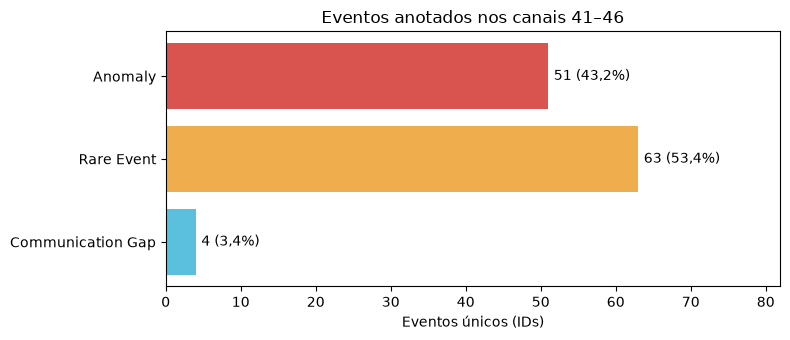

Total: 118 eventos únicos em 1255 intervalos anotados.


In [13]:
ordem_categorias = ["Anomaly", "Rare Event", "Communication Gap"]
contagem_eventos_categoria = eventos_unicos["Category"].value_counts()
categorias_extra = [
    categoria
    for categoria in contagem_eventos_categoria.index
    if categoria not in ordem_categorias
]
ordem_categorias.extend(categorias_extra)
contagem_eventos_categoria = contagem_eventos_categoria.reindex(
    ordem_categorias, fill_value=0
)

resumo_eventos = pd.DataFrame(
    {
        "Categoria": contagem_eventos_categoria.index,
        "Eventos únicos": contagem_eventos_categoria.values,
        "Percentual": (
            contagem_eventos_categoria.values
            / contagem_eventos_categoria.sum()
            * 100
        ).round(1),
    }
)
display(resumo_eventos)

fig, ax = plt.subplots(figsize=(8, 3.5))
bar_colors = [CORES_CATEGORIAS.get(c, "#777777") for c in resumo_eventos["Categoria"]]
bars = ax.barh(resumo_eventos["Categoria"], resumo_eventos["Eventos únicos"], color=bar_colors)
ax.invert_yaxis()
ax.set_xlabel("Eventos únicos (IDs)")
ax.set_title("Eventos anotados nos canais 41–46")

# MUDANÇA: o rótulo agora mostra o número e a porcentagem
rotulos = [
    f"{n} ({p:.1f}%)".replace(".", ",")
    for n, p in zip(resumo_eventos["Eventos únicos"], resumo_eventos["Percentual"])
]
ax.bar_label(bars, labels=rotulos, padding=4)
ax.set_xlim(0, max(resumo_eventos["Eventos únicos"].max() * 1.3, 1))
plt.tight_layout()
plt.show()

print(
    f"Total: {eventos_unicos['ID'].nunique()} eventos únicos "
    f"em {len(labels_clean)} intervalos anotados."
)

**Resposta.** Nos canais 41–46 há **118 eventos únicos**: 51 anomalias (43,2%), 63 eventos nominais raros (53,4%) e 4 lacunas de comunicação (3,4%). Esses eventos aparecem em 1.255 intervalos anotados porque um ID pode ter registros em vários canais e em vários trechos. As lacunas são uma categoria separada, não devem ser somadas a anomalias nem a eventos nominais raros ao responder perguntas específicas sobre essas duas classes.

**1.2 Qual é o intervalo entre o primeiro início e o último fim anotados de cada anomalia ou evento nominal raro? Como a distribuição se compara?**

> A tabela mostra mediana e quartis em unidades legíveis; o gráfico agrupa os eventos por faixas de tempo. Essa medida é o **envelope dos rótulos** (do primeiro início ao último fim), não necessariamente a duração contínua de um fenômeno. Alguns IDs podem ter intervalos anotados separados; veja a tabela de envelope versus união logo abaixo. `StartTime = EndTime` significa anotação pontual, não duração física zero.

,n,início = fim,mediana,1º quartil,3º quartil,mínimo,máximo
Category,,,,,,,
Anomaly,51,10,13 s,2 s,16 h 07 min,0 s,28 d 9 h
Rare Event,63,1,1 h 32 min,31 min,6 h 37 min,0 s,19 d 21 h


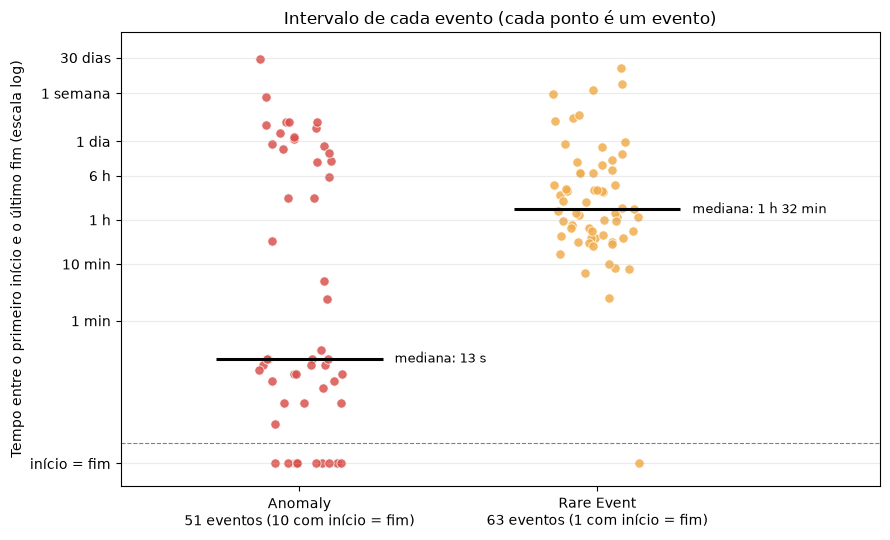

faixa,Menos de 1 min,1 min a 1 h,1 h a 1 dia,Mais de 1 dia
Category,,,,
Anomaly,29,3,9,10
Rare Event,1,23,32,7


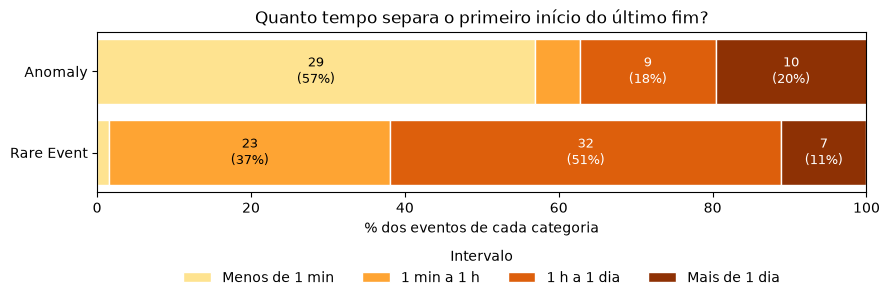

O intervalo é calculado entre datas anotadas e pode incluir trechos sem anotação.
A faixa 'Menos de 1 min' inclui os eventos com início = fim.


In [14]:
categorias_duracao = ["Anomaly", "Rare Event"]
duracoes_eventos = eventos_unicos.loc[
    eventos_unicos["Category"].isin(categorias_duracao),
    ["ID", "Category", "intervalo_total"],
].copy()
duracoes_eventos["horas_entre_datas"] = (
    duracoes_eventos["intervalo_total"].dt.total_seconds() / 3600
)


def formatar_duracao(horas):
    """Escreve uma duração (dada em horas) em unidades fáceis de ler."""
    segundos = horas * 3600
    if segundos == 0:
        return "0 s"
    if segundos < 1:
        return "< 1 s"
    if segundos < 60:
        return f"{segundos:.0f} s"
    minutos_totais = int(round(segundos / 60))
    if minutos_totais < 60:
        return f"{minutos_totais} min"
    if horas < 24:
        h, m = divmod(minutos_totais, 60)
        return f"{h} h {m:02d} min"
    horas_totais = int(round(horas))
    d, h = divmod(horas_totais, 24)
    return f"{d} d {h} h"


# ---------- Tabela-resumo ----------
resumo_duracoes = (
    duracoes_eventos.groupby("Category")["horas_entre_datas"]
    .agg(
        n="count",
        n_zero=lambda valores: int((valores == 0).sum()),
        mediana_horas="median",
        q1_horas=lambda valores: valores.quantile(0.25),
        q3_horas=lambda valores: valores.quantile(0.75),
        minimo_horas="min",
        maximo_horas="max",
    )
    .reindex(categorias_duracao)
)

# MUDANÇA: a tabela mostra as durações em segundos/minutos/horas/dias,
# e não mais em horas arredondadas (que mostravam 0,00 para a mediana das anomalias).
resumo_legivel = resumo_duracoes.copy()
for coluna in ["mediana_horas", "q1_horas", "q3_horas", "minimo_horas", "maximo_horas"]:
    resumo_legivel[coluna] = resumo_legivel[coluna].map(formatar_duracao)
resumo_legivel.columns = ["n", "início = fim", "mediana", "1º quartil", "3º quartil", "mínimo", "máximo"]
display(resumo_legivel)

# ---------- Gráfico A: cada ponto é um evento ----------
menor_positivo = duracoes_eventos.loc[
    duracoes_eventos["horas_entre_datas"] > 0, "horas_entre_datas"
].min()
PISO = menor_positivo / 5          # posição desenhada para os eventos com início = fim
LINHA_SEPARADORA = menor_positivo / 2.2

fig, ax = plt.subplots(figsize=(9, 5.5))
rng_duracao = np.random.default_rng(42)
for posicao, categoria in enumerate(categorias_duracao, start=1):
    valores = duracoes_eventos.loc[
        duracoes_eventos["Category"] == categoria, "horas_entre_datas"
    ]
    y = valores.where(valores > 0, PISO)       # MUDANÇA: zeros ficam numa faixa própria
    jitter = rng_duracao.uniform(-0.15, 0.15, size=len(y))
    ax.scatter(
        posicao + jitter, y,
        color=CORES_CATEGORIAS[categoria],
        edgecolor="white", linewidth=0.6, alpha=0.85, s=45,
    )
    # MUDANÇA: traço preto = mediana de cada categoria
    mediana = valores.median()
    y_mediana = max(mediana, PISO)
    ax.hlines(y_mediana, posicao - 0.28, posicao + 0.28, color="black", linewidth=2.2)
    ax.text(
        posicao + 0.32, y_mediana, f"mediana: {formatar_duracao(mediana)}",
        va="center", fontsize=9,
    )

ax.axhline(LINHA_SEPARADORA, color="gray", linestyle="--", linewidth=0.8)
ax.set_yscale("log")
marcas = [PISO, 1/60, 10/60, 1, 6, 24, 168, 720]
nomes = ["início = fim", "1 min", "10 min", "1 h", "6 h", "1 dia", "1 semana", "30 dias"]
ax.set_yticks(marcas)
ax.set_yticklabels(nomes)
ax.minorticks_off()
ax.set_ylim(PISO / 2.5, 2000)
ax.set_xlim(0.4, 2.95)
ax.set_xticks([1, 2])
ax.set_xticklabels(
    [
        f"Anomaly\n{int(resumo_duracoes.loc['Anomaly', 'n'])} eventos "
        f"({int(resumo_duracoes.loc['Anomaly', 'n_zero'])} com início = fim)",
        f"Rare Event\n{int(resumo_duracoes.loc['Rare Event', 'n'])} eventos "
        f"({int(resumo_duracoes.loc['Rare Event', 'n_zero'])} com início = fim)",
    ]
)
ax.set_ylabel("Tempo entre o primeiro início e o último fim (escala log)")
ax.set_title("Intervalo de cada evento (cada ponto é um evento)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ---------- Gráfico B: resumo por faixas (mais simples de ler) ----------
limites = [-0.1, 1 / 60, 1, 24, np.inf]    # em horas; -0,1 faz o zero entrar na 1ª faixa
rotulos_faixas = ["Menos de 1 min", "1 min a 1 h", "1 h a 1 dia", "Mais de 1 dia"]
duracoes_eventos["faixa"] = pd.cut(
    duracoes_eventos["horas_entre_datas"],
    bins=limites, labels=rotulos_faixas, right=False,
)
tabela_faixas = (
    pd.crosstab(duracoes_eventos["Category"], duracoes_eventos["faixa"])
    .reindex(index=categorias_duracao, columns=rotulos_faixas, fill_value=0)
)
percentuais = tabela_faixas.div(tabela_faixas.sum(axis=1), axis=0) * 100
display(tabela_faixas)

fig, ax = plt.subplots(figsize=(9, 3.4))
cores_faixas = plt.cm.YlOrBr(np.linspace(0.25, 0.9, len(rotulos_faixas)))
esquerda = np.zeros(len(categorias_duracao))
for i, faixa in enumerate(rotulos_faixas):
    larguras = percentuais[faixa].to_numpy()
    ax.barh(categorias_duracao, larguras, left=esquerda,
            color=cores_faixas[i], edgecolor="white", label=faixa)
    for j, (largura, inicio_barra) in enumerate(zip(larguras, esquerda)):
        if largura >= 6:
            n = int(tabela_faixas.iloc[j][faixa])
            ax.text(
                inicio_barra + largura / 2, j, f"{n}\n({largura:.0f}%)",
                ha="center", va="center", fontsize=9,
                color="white" if i >= 2 else "black",
            )
    esquerda += larguras
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% dos eventos de cada categoria")
ax.set_title("Quanto tempo separa o primeiro início do último fim?")
ax.legend(title="Intervalo", ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.28), frameon=False)
plt.tight_layout()
plt.show()

print("O intervalo é calculado entre datas anotadas e pode incluir trechos sem anotação.")
print("A faixa 'Menos de 1 min' inclui os eventos com início = fim.")

In [15]:
def duracao_uniao(intervalos):
    intervalos_ordenados = sorted(intervalos, key=lambda par: par[0])
    if not intervalos_ordenados:
        return pd.Timedelta(0)

    inicio_atual, fim_atual = intervalos_ordenados[0]
    duracao_total = pd.Timedelta(0)
    for novo_inicio, novo_fim in intervalos_ordenados[1:]:
        if novo_inicio <= fim_atual:
            fim_atual = max(fim_atual, novo_fim)
        else:
            duracao_total += fim_atual - inicio_atual
            inicio_atual, fim_atual = novo_inicio, novo_fim
    return duracao_total + (fim_atual - inicio_atual)

linhas_duracao_uniao = []
for evento_id, grupo in labels_clean.groupby("ID"):
    pares = list(zip(grupo["StartTimeUTC"], grupo["EndTimeUTC"]))
    linhas_duracao_uniao.append({
        "ID": evento_id,
        "duracao_uniao": duracao_uniao(pares),
    })
duracoes_uniao = pd.DataFrame(linhas_duracao_uniao)
comparacao_duracao = eventos_unicos[["ID", "Category", "intervalo_total"]].merge(
    duracoes_uniao, on="ID", validate="one_to_one"
)
comparacao_duracao["tempo_sem_anotacao_no_envelope"] = (
    comparacao_duracao["intervalo_total"] - comparacao_duracao["duracao_uniao"]
)
if (comparacao_duracao["tempo_sem_anotacao_no_envelope"] < pd.Timedelta(0)).any():
    raise ValueError("A união calculada excede o envelope temporal de algum evento.")
print("Maiores tempos sem anotação dentro do envelope temporal do evento:")
display(
    comparacao_duracao.sort_values(
        "tempo_sem_anotacao_no_envelope", ascending=False
    ).head(10)
)

Maiores tempos sem anotação dentro do envelope temporal do evento:


,ID,Category,intervalo_total,duracao_uniao,tempo_sem_anotacao_no_envelope
27,id_134,Anomaly,28 days 08:58:41.997000,14 days 07:59:34.497000,14 days 00:59:07.500000
69,id_21,Rare Event,10 days 09:06:59.997000,0 days 06:54:30.003000,10 days 02:12:29.994000
59,id_180,Rare Event,2 days 23:09:00,0 days 09:43:22.500000,2 days 13:25:37.500000
52,id_17,Rare Event,2 days 15:03:00,0 days 02:09:00,2 days 12:54:00
42,id_155,Rare Event,2 days 06:06:30,0 days 00:12:52.500000,2 days 05:53:37.500000
102,id_78,Rare Event,8 days 01:26:00,6 days 08:35:30,1 days 16:50:30
72,id_24,Rare Event,0 days 23:29:30,0 days 00:54:00,0 days 22:35:30
39,id_151,Rare Event,0 days 19:02:00,0 days 05:26:30,0 days 13:35:30
37,id_15,Rare Event,0 days 09:02:30,0 days 00:10:00,0 days 08:52:30
6,id_104,Rare Event,0 days 07:31:30,0 days 00:16:00,0 days 07:15:30


**Resposta.** Os intervalos variam muito, e as **anomalias se dividem em dois grupos**:

- **Anomalias muito curtas:** 29 das 51 anomalias têm intervalo menor que 1 minuto. Dessas, 10 têm início exatamente igual ao fim, e as demais duram poucos segundos. A mediana das anomalias é 13 segundos; ela **não é zero**, apenas pequena.
- **Anomalias longas:** as outras vão de alguns minutos até cerca de 28 dias (maior valor: 28 d 9 h). O 3º quartil das anomalias é 16 h 07 min.
- **Eventos nominais raros:** formam um grupo só. A mediana é 1 h 32 min, metade dos eventos fica entre 31 min e 6 h 37 min, e o maior intervalo é 19 d 21 h. Só 1 dos 63 tem início igual ao fim, e apenas 1 têm intervalo menor que 1 minuto.

**Observação.** Intervalos muito curtos aparecem quase só em anomalias. Isso pode indicar que parte das anomalias é **pontual** (acontece em um instante, e a diferença de segundos vem do horário de cada canal), mas isso ainda precisa ser confirmado, por exemplo com a coluna `Length` de `anomaly_types.csv` (calculada para a missão inteira). Como são poucos eventos, trate como uma observação e não como regra.

**1.3 Existem eventos que afetam vários canais ao mesmo tempo (mesmo ID em múltiplos canais)? Com que frequência isso acontece?**

Category,Anomaly,Rare Event,Communication Gap
canais_afetados,,,
1,1,0,0
2,0,0,0
3,0,1,0
4,0,1,0
5,1,1,0
6,49,60,4


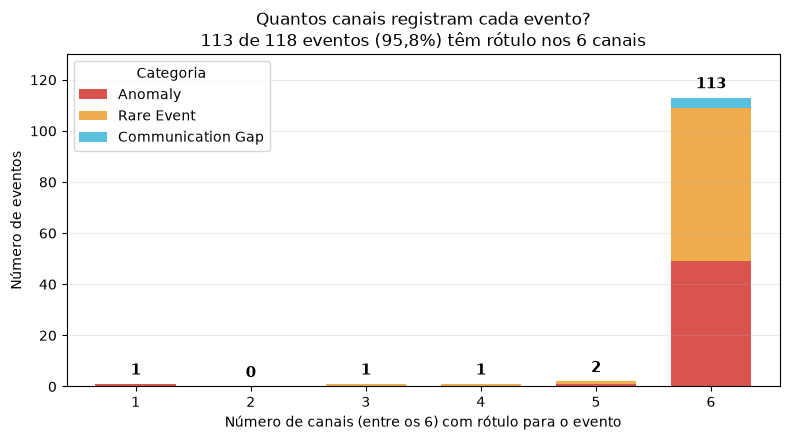

,ID,Category,canais_afetados
87,id_42,Anomaly,1
97,id_55,Rare Event,3
86,id_41,Rare Event,4
43,id_157,Anomaly,5
83,id_38,Rare Event,5


id_42 (Anomaly): sem rótulo em channel_42, channel_43, channel_44, channel_45, channel_46.
id_55 (Rare Event): sem rótulo em channel_42, channel_44, channel_46.
id_41 (Rare Event): sem rótulo em channel_43, channel_44.
id_157 (Anomaly): sem rótulo em channel_46.
id_38 (Rare Event): sem rótulo em channel_46.
Eventos com rótulo em mais de um canal: 117 de 118.
Eventos com rótulo nos seis canais: 113 de 118.
A tabela lista apenas eventos sem rótulo nos seis canais disponíveis.


In [16]:
ordem_eventos = (
    eventos_unicos.assign(
        numero_id=eventos_unicos["ID"].str.extract(r"(\d+)", expand=False).astype(int)
    )
    .sort_values(["Category", "numero_id"])
    ["ID"]
    .tolist()
)

# Cada par evento-canal é contado uma vez, mesmo que o canal tenha vários trechos.
eventos_canais = labels_clean[["ID", "Channel"]].drop_duplicates()
matriz_evento_canal = pd.crosstab(
    eventos_canais["ID"], eventos_canais["Channel"]
).reindex(index=ordem_eventos, columns=canais_disponiveis, fill_value=0)
matriz_evento_canal = matriz_evento_canal.gt(0)

resumo_canais_evento = eventos_unicos[["ID", "Category"]].copy()
resumo_canais_evento["canais_afetados"] = matriz_evento_canal.sum(axis=1).reindex(
    resumo_canais_evento["ID"]
).to_numpy()

distribuicao_canais = pd.crosstab(
    resumo_canais_evento["canais_afetados"], resumo_canais_evento["Category"]
).reindex(index=range(1, len(canais_disponiveis) + 1), fill_value=0)
distribuicao_canais = distribuicao_canais.reindex(columns=ordem_categorias, fill_value=0)
display(distribuicao_canais)

n_multicanal = int((resumo_canais_evento["canais_afetados"] > 1).sum())
n_todos_canais = int((resumo_canais_evento["canais_afetados"] == len(canais_disponiveis)).sum())
pct_todos = n_todos_canais / len(eventos_unicos) * 100

# MUDANÇAS: barras empilhadas (em vez de lado a lado), número escrito em cima de
# TODAS as barras (inclusive as de valor 1) e o resumo principal no subtítulo.
fig, ax = plt.subplots(figsize=(8, 4.5))
distribuicao_canais.plot(
    kind="bar", stacked=True, ax=ax, width=0.7,
    color=[CORES_CATEGORIAS.get(c, "#777777") for c in distribuicao_canais.columns],
)
totais = distribuicao_canais.sum(axis=1)
for posicao, total in enumerate(totais):
    ax.text(posicao, total + totais.max() * 0.02, str(int(total)),
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylim(0, totais.max() * 1.15)
ax.set_xlabel("Número de canais (entre os 6) com rótulo para o evento")
ax.set_ylabel("Número de eventos")
ax.set_title(
    "Quantos canais registram cada evento?\n"
    f"{n_todos_canais} de {len(eventos_unicos)} eventos "
    f"({pct_todos:.1f}%) têm rótulo nos 6 canais".replace(".", ","),
)
ax.legend(title="Categoria", loc="upper left")
ax.set_xticklabels(distribuicao_canais.index, rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

canais_por_id = eventos_canais.groupby("ID")["Channel"].agg(list)
eventos_incompletos = resumo_canais_evento.loc[
    resumo_canais_evento["canais_afetados"] < len(canais_disponiveis)
].copy()
eventos_incompletos = eventos_incompletos.sort_values(["canais_afetados", "Category", "ID"])
display(eventos_incompletos)

for _, linha in eventos_incompletos.iterrows():
    canais_sem_rotulo = [
        canal for canal in canais_disponiveis if canal not in canais_por_id[linha["ID"]]
    ]
    print(
        f"{linha['ID']} ({linha['Category']}): sem rótulo em "
        f"{', '.join(canais_sem_rotulo)}."
    )

print(f"Eventos com rótulo em mais de um canal: {n_multicanal} de {len(eventos_unicos)}.")
print(f"Eventos com rótulo nos seis canais: {n_todos_canais} de {len(eventos_unicos)}.")
print("A tabela lista apenas eventos sem rótulo nos seis canais disponíveis.")

**Resposta.** Quase todos os eventos são multicanal: **117 de 118** aparecem em mais de um canal, e **113 (95,8%)** aparecem nos seis. Os 5 casos restantes são: 1 anomalia em um canal, 1 evento raro em três canais, 1 evento raro em quatro e 2 eventos em cinco (um raro e uma anomalia). Isso sugere que os rótulos deste recorte são majoritariamente compartilhados entre os canais, mas não prova que os sinais mudem exatamente ao mesmo tempo; a comparação dos horários de início será feita na pergunta 2.2.

Dois desses casos, `id_55` e `id_157`, estão entre os eventos que o artigo do ESA-ADB (Kotowski et al., 2024) cita como difíceis de ver usando apenas os canais 41–46. "Sem rótulo" significa que não há anotação para aquele ID naquele canal, e não necessariamente que o sinal não mudou.

**1.4 Há concentração de eventos em algum período da linha do tempo anonimizada (2000–2013), ou as ocorrências parecem distribuídas ao longo do recorte?**

Category,Anomaly,Rare Event,Communication Gap
ano_anotado,,,
2000,5,5,0
2001,0,7,3
2002,4,1,1
2003,3,3,0
2004,2,4,0
2005,4,5,0
2006,4,2,0
2007,5,8,0
2008,3,4,0


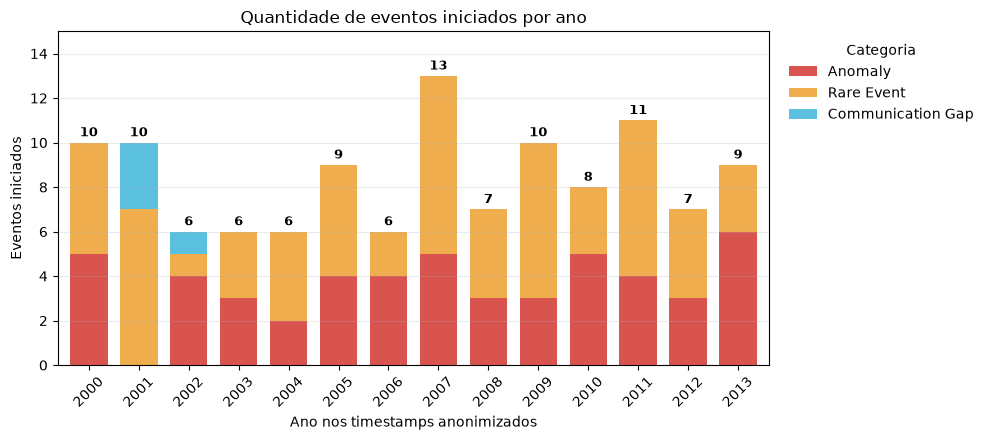

Maior contagem anual: 13 eventos, no(s) ano(s) anotado(s) [2007].
Divisão treino/teste (aproximada): 2006-12-31
Eventos que começam antes: 53 | depois: 65


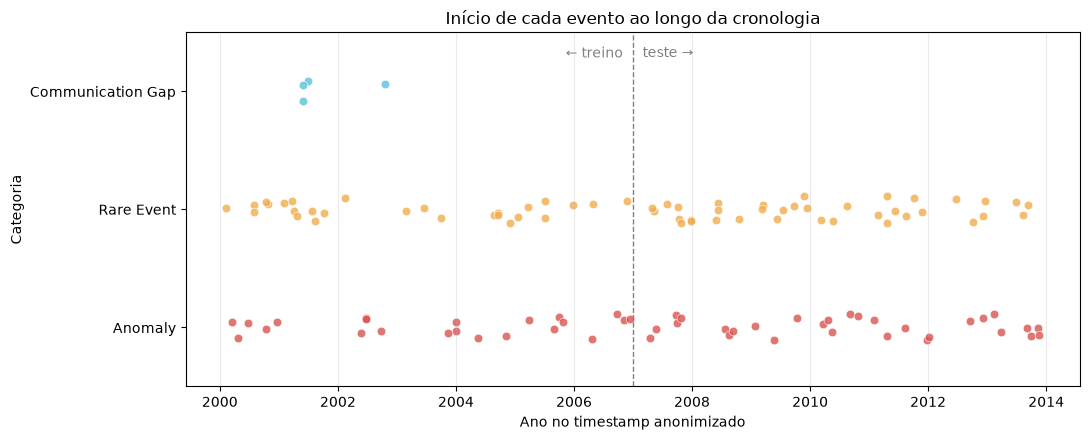

Cada ponto representa o início de um ID; a posição vertical é levemente deslocada apenas para separar pontos próximos. As datas são anonimizadas e não representam o calendário real da missão.


,ID,inicio_utc,fim_utc,intervalo_total
94,id_52,2001-05-27 18:45:58.296000+00:00,2001-05-28 14:30:28.296000+00:00,0 days 19:44:30
95,id_53,2001-06-27 08:13:55.296000+00:00,2001-06-27 09:02:25.296000+00:00,0 days 00:48:30
96,id_54,2002-10-16 05:59:55.242000+00:00,2002-10-16 11:54:25.242000+00:00,0 days 05:54:30
98,id_57,2001-05-30 22:24:28.296000+00:00,2001-05-31 11:27:58.296000+00:00,0 days 13:03:30


In [17]:
eventos_tempo = eventos_unicos.dropna(subset=["inicio_utc"]).copy()
eventos_tempo["ano_anotado"] = eventos_tempo["inicio_utc"].dt.year
# Para os gráficos de data, usamos o horário sem fuso (evita incompatibilidade com a série).
eventos_tempo["inicio_plot"] = eventos_tempo["inicio_utc"].dt.tz_localize(None)

contagem_anual = pd.crosstab(
    eventos_tempo["ano_anotado"], eventos_tempo["Category"]
).reindex(columns=ordem_categorias, fill_value=0)
anos_completos = range(
    int(eventos_tempo["ano_anotado"].min()),
    int(eventos_tempo["ano_anotado"].max()) + 1,
)
contagem_anual = contagem_anual.reindex(anos_completos, fill_value=0)
display(contagem_anual)

total_por_ano = contagem_anual.sum(axis=1)

# ---------- Gráfico A: eventos por ano ----------
fig, ax = plt.subplots(figsize=(10, 4.5))
contagem_anual.plot(
    kind="bar", stacked=True, ax=ax, width=0.75,
    color=[CORES_CATEGORIAS.get(c, "#777777") for c in contagem_anual.columns],
)
# MUDANÇA: total escrito em cima de cada barra
for posicao, total in enumerate(total_por_ano):
    ax.text(posicao, total + 0.15, str(int(total)),
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_ylim(0, total_por_ano.max() + 2)        # MUDANÇA: espaço acima da maior barra
ax.set_xlabel("Ano nos timestamps anonimizados")
ax.set_ylabel("Eventos iniciados")
ax.set_title("Quantidade de eventos iniciados por ano")
# MUDANÇA: legenda fora do gráfico, para não cobrir as barras
ax.legend(title="Categoria", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

max_eventos_ano = int(total_por_ano.max())
anos_pico = total_por_ano.index[total_por_ano == max_eventos_ano].tolist()
print(f"Maior contagem anual: {max_eventos_ano} eventos, no(s) ano(s) anotado(s) {anos_pico}.")

# ---------- Gráfico B: início de cada evento na linha do tempo ----------
# MUDANÇA: linha vertical na divisão treino/teste. O artigo usa a primeira metade
# do período para treino; aqui a divisão é o ponto médio da série do channel_41.
data_corte = ch41.index.min() + (ch41.index.max() - ch41.index.min()) / 2
# convertemos a data de corte para o mesmo formato antes de comparar.
if data_corte.tzinfo is not None:
    data_corte = data_corte.tz_convert("UTC").tz_localize(None)
antes = int((eventos_tempo["inicio_plot"] < data_corte).sum())
depois = int((eventos_tempo["inicio_plot"] >= data_corte).sum())
print(f"Divisão treino/teste (aproximada): {data_corte.date()}")
print(f"Eventos que começam antes: {antes} | depois: {depois}")

fig, ax = plt.subplots(figsize=(11, 4.5))
rng_tempo = np.random.default_rng(42)
for posicao, categoria in enumerate(ordem_categorias):
    datas_inicio = eventos_tempo.loc[eventos_tempo["Category"] == categoria, "inicio_plot"]
    deslocamento_vertical = rng_tempo.uniform(-0.12, 0.12, size=len(datas_inicio))
    ax.scatter(
        datas_inicio, posicao + deslocamento_vertical,
        color=CORES_CATEGORIAS.get(categoria, "#777777"),
        s=38, alpha=0.8, edgecolor="white", linewidth=0.5,
    )

ax.axvline(data_corte, color="gray", linestyle="--", linewidth=1)
ax.text(data_corte - pd.Timedelta(days=60), 0.96, "← treino", ha="right", va="top",
        transform=ax.get_xaxis_transform(), color="gray", fontsize=10)
ax.text(data_corte + pd.Timedelta(days=60), 0.96, "teste →", ha="left", va="top",
        transform=ax.get_xaxis_transform(), color="gray", fontsize=10)

ax.set_yticks(range(len(ordem_categorias)), ordem_categorias)
ax.set_ylim(-0.5, len(ordem_categorias) - 0.5)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Ano no timestamp anonimizado")
ax.set_ylabel("Categoria")
ax.set_title("Início de cada evento ao longo da cronologia")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Cada ponto representa o início de um ID; a posição vertical é levemente deslocada "
    "apenas para separar pontos próximos. As datas são anonimizadas e não representam "
    "o calendário real da missão."
)

# ---------- Conferência: datas das lacunas de comunicação ----------
display(
    eventos_unicos.loc[
        eventos_unicos["Category"] == "Communication Gap",
        ["ID", "inicio_utc", "fim_utc", "intervalo_total"],
    ]
)

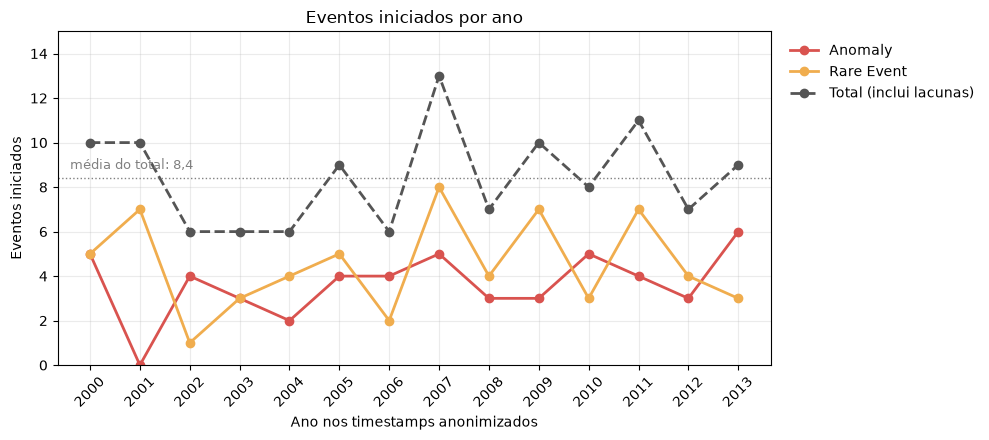

As 4 lacunas de comunicação não têm linha própria (quase todos os anos têm 0), mas estão somadas no total.


In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
anos = contagem_anual.index

for categoria in ["Anomaly", "Rare Event"]:
    ax.plot(anos, contagem_anual[categoria], marker="o", linewidth=2,
            color=CORES_CATEGORIAS[categoria], label=categoria)
ax.plot(anos, total_por_ano, marker="o", linewidth=2, linestyle="--",
        color="#555555", label="Total (inclui lacunas)")

# Linha pontilhada = média anual do total: mostra quais anos ficam acima ou abaixo do normal
media_total = total_por_ano.mean()
ax.axhline(media_total, color="gray", linestyle=":", linewidth=1)
ax.text(anos.min() - 0.4, media_total + 0.25,
        f"média do total: {media_total:.1f}".replace(".", ","),
        fontsize=9, color="gray", va="bottom")

ax.set_xticks(list(anos))
ax.set_xticklabels(anos, rotation=45)
ax.set_ylim(0, total_por_ano.max() + 2)
ax.set_xlabel("Ano nos timestamps anonimizados")
ax.set_ylabel("Eventos iniciados")
ax.set_title("Eventos iniciados por ano")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
print("As 4 lacunas de comunicação não têm linha própria (quase todos os anos têm 0), mas estão somadas no total.")

**Resposta.** Não há um período que concentre os eventos. Os 118 eventos começam em todos os anos de 2000 a 2013, com média de **8,4 eventos por ano** (mediana 8,5). A contagem anual varia de 6 a 13, e 12 dos 14 anos ficam entre 6 e 10 eventos.

**O que os gráficos mostram**

- **Total por ano:** o maior valor é 2007, com 13 eventos (11% do total), seguido de 2011, com 11. O menor valor, 6 eventos, ocorre em 2002, 2003, 2004 e 2006.
- **Anomalias:** são regulares. Ficam entre 2 e 6 por ano, com uma exceção: 2001 não tem nenhuma. No gráfico de pontos, não aparecem anomalias entre o final de 2000 e meados de 2002.
- **Eventos raros:** variam mais, de 1 (em 2002) a 8 (em 2007) por ano. O pico de 2007 vem principalmente deles: são 8 eventos raros e 5 anomalias.
- **Lacunas de comunicação:** são 4, três em 2001 e uma em 2002. Todas estão na primeira metade do período.
- **Gráfico de linhas:** confirma que as anomalias oscilam pouco e os eventos raros oscilam mais. Os zigue-zagues entre um ano e outro mostram variação de ano para ano e não devem ser lidos como tendência de aumento ou queda.

**Antes e depois da divisão treino/teste.** Dividindo o período ao meio (cerca de 2006-12-31, o ponto médio da série), 53 eventos começam na primeira metade (44,9%) e 65 na segunda (55,1%).

| Período | Anomalias | Eventos raros | Lacunas | Total |
|---|---|---|---|---|
| 2000–2006 | 22 | 27 | 4 | 53 |
| 2007–2013 | 29 | 36 | 0 | 65 |

As duas metades têm anomalias e eventos raros, em quantidades parecidas.

**Conferência das lacunas de comunicação.** As três lacunas de 2001 ocorrem nas mesmas datas em que o artigo do ESA-ADB (Kotowski et al., 2024) descreve mudanças bruscas na frequência de amostragem dos canais 41–46:

| Evento | Início → fim da lacuna | Data citada no artigo |
|---|---|---|
| `id_52` | 2001-05-27 → 2001-05-28 | 2001-05-28 |
| `id_57` | 2001-05-30 → 2001-05-31 | 2001-05-31 |
| `id_53` | 2001-06-27 (48 min) | 2001-06-27 |

A quarta lacuna (`id_54`, 2002-10-16, cerca de 6 h) não tem relação com essas datas. A coincidência sugere que as lacunas rotuladas em 2001 estejam ligadas a essas mudanças de amostragem, mas isso **não está confirmado**: o artigo afirma que esses episódios não foram anotados, e aqui eles aparecem como `Communication Gap`. Essa diferença será verificada na pergunta 2.4, olhando o intervalo entre leituras nessas datas.

**Como interpretar com cuidado**

- A análise é descritiva: compara contagens anuais, sem teste estatístico. Como referência simples, se os eventos fossem sorteados ao acaso entre os anos, a variação típica em torno da média seria de cerca de 2,9 eventos por ano. A variação observada é de 2,2, ou seja, não é maior do que o esperado ao acaso.
- A contagem por ano é um nível grosseiro. Ela não mostra se há eventos agrupados em semanas ou meses dentro de um mesmo ano.
- O gráfico mostra **quando os eventos foram anotados**, e não necessariamente quando mais ocorreram. Mais anotações em um período podem refletir mais eventos ou mais atenção na revisão.
- As datas são anonimizadas: os gráficos mostram a ordem e a distribuição relativa, não o calendário real da missão.

**Conclusão para a pesquisa.** Os eventos estão distribuídos ao longo de todo o período, e as duas metades têm anomalias e eventos raros. As análises seguintes, portanto, não ficam restritas a uma fase específica.

#### 2. Comportamento dos canais durante eventos

**2.1 Como o `channel_41` se comporta durante algumas anomalias e eventos raros, comparado com trechos próximos sem rótulo?**

> Serão mostrados três exemplos de anomalia e dois de evento raro, escolhidos para cobrir durações diferentes. Cada painel usa no máximo 24 horas a partir do início do intervalo anotado; o painel de comparação mostra um trecho próximo de mesmo tamanho que não cruza nenhum rótulo do `channel_41`. Ausência de rótulo não garante que o comportamento seja normal.

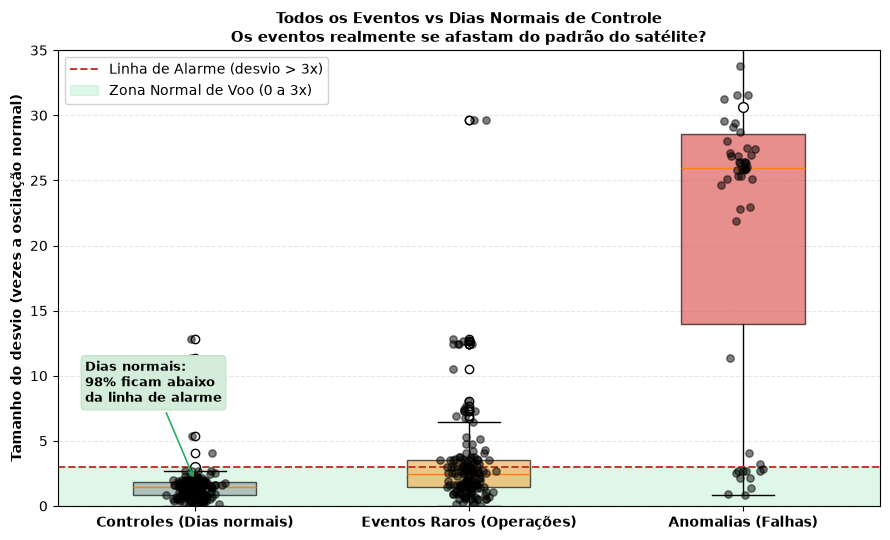

--- Resumo Estatístico Global (Evento × Controle) ---


,Total,Mediana,Alarmariam_Maior_3x
tipo,,,
Controles (Dias normais),191,1.483677,4.2%
Eventos Raros (Operações),154,2.428050,32.5%
Anomalias (Falhas),54,25.966352,79.6%


In [19]:
canal_visual = "channel_41"
serie_visual = pd.to_numeric(
    channels[canal_visual].iloc[:, 0], errors="coerce"
).dropna()

# 1. Definimos o comportamento normal do canal (mediana e desvio robusto MAD)
mediana_global = float(serie_visual.loc[serie_visual > 0].median())
mad_global = 1.4826 * float(
    (serie_visual.loc[serie_visual > 0] - mediana_global).abs().median()
)

# 2. Filtramos todos os eventos rotulados deste canal
rotulos_21 = labels_rotuladas.loc[
    (labels_rotuladas["Channel"] == canal_visual)
    & labels_rotuladas["Category"].isin(["Anomaly", "Rare Event"])
].copy()
rotulos_21["inicio"] = pd.to_datetime(
    rotulos_21["StartTimeUTC"], utc=True
).dt.tz_localize(None)
rotulos_21["fim"] = pd.to_datetime(
    rotulos_21["EndTimeUTC"], utc=True
).dt.tz_localize(None)

# 3. Calculamos o desvio máximo para cada evento real e para trechos de controle (dias comuns)
np.random.seed(42)
registros_comparacao = []

for _, ev in rotulos_21.iterrows():
    # Desvio durante o evento real
    trecho_evento = serie_visual.loc[ev["inicio"] : ev["fim"]]
    if len(trecho_evento) > 0:
        score_evento = float(
            (trecho_evento - mediana_global).abs().max() / mad_global
        )
    else:
        score_evento = np.nan

    registros_comparacao.append(
        {
            "tipo": (
                "Anomalias (Falhas)"
                if ev["Category"] == "Anomaly"
                else "Eventos Raros (Operações)"
            ),
            "desvio_max": score_evento,
        }
    )

    # Criamos um "trecho de controle" com a mesma duração em um período normal (7 dias antes)
    duracao_ev = ev["fim"] - ev["inicio"]
    ini_ctrl = ev["inicio"] - pd.Timedelta(days=7)
    fim_ctrl = ini_ctrl + duracao_ev
    trecho_ctrl = serie_visual.loc[ini_ctrl:fim_ctrl]

    if len(trecho_ctrl) > 0:
        score_ctrl = float(
            (trecho_ctrl - mediana_global).abs().max() / mad_global
        )
        registros_comparacao.append(
            {"tipo": "Controles (Dias normais)", "desvio_max": score_ctrl}
        )

df_comp = pd.DataFrame(registros_comparacao).dropna()

# ------------------------------------------------------------------------------
# Gráfico Comparativo: Controles vs Eventos Raros vs Anomalias
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

ordem_grupos = [
    "Controles (Dias normais)",
    "Eventos Raros (Operações)",
    "Anomalias (Falhas)",
]
cores_grupos = ["#95a5a6", CORES_CATEGORIAS["Rare Event"], CORES_CATEGORIAS["Anomaly"]]

dados_grupos = [
    df_comp.loc[df_comp["tipo"] == g, "desvio_max"] for g in ordem_grupos
]

bp = ax.boxplot(
    dados_grupos,
    patch_artist=True,
    widths=0.45,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7,
    },
)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(ordem_grupos, fontsize=10, fontweight="bold")

for patch, cor in zip(bp["boxes"], cores_grupos):
    patch.set_facecolor(cor)
    patch.set_alpha(0.65)

# Pontos reais individuais
for i, valores in enumerate(dados_grupos):
    np.random.seed(42)
    x = np.random.normal(i + 1, 0.04, size=len(valores))
    ax.scatter(x, valores, color="black", alpha=0.5, s=28, zorder=3)

# Linha de Alarme tradicional e Faixa Normal
ax.axhline(
    3,
    color="#c0392b",
    linestyle="--",
    linewidth=1.4,
    label="Linha de Alarme (desvio > 3x)",
)
ax.axhspan(0, 3, color="#2ecc71", alpha=0.15, label="Zona Normal de Voo (0 a 3x)")

# Focamos no intervalo de 0 a 35 para garantir máxima clareza
ax.set_ylim(0, 35)
ax.set_ylabel(
    "Tamanho do desvio (vezes a oscilação normal)",
    fontsize=10,
    fontweight="bold",
)
ax.set_title(
    "Todos os Eventos vs Dias Normais de Controle\nOs eventos realmente se afastam do padrão do satélite?",
    fontsize=11,
    fontweight="bold",
)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(loc="upper left", framealpha=0.9)

# Anotação explicando os Controles
ax.annotate(
    "Dias normais:\n98% ficam abaixo\nda linha de alarme",
    xy=(1, 2),
    xytext=(0.6, 8),
    arrowprops=dict(arrowstyle="->", color="#27ae60", lw=1.2),
    fontsize=9,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="#d4edda", ec="#c3e6cb"),
)

plt.tight_layout()
plt.show()

# Tabela com as porcentagens de alarme por grupo
resumo_comp = (
    df_comp.groupby("tipo")["desvio_max"]
    .agg(
        Total="count",
        Mediana="median",
        Alarmariam_Maior_3x=lambda s: f"{(s > 3).mean()*100:.1f}%",
    )
    .reindex(ordem_grupos)
)
print("--- Resumo Estatístico Global (Evento × Controle) ---")
display(resumo_comp)

Entendendo os dados:
- Dias normais (Controle): Em condições rotineiras de voo, o satélite é muito estável. Mais de 95% dos períodos normais permanecem dentro da faixa esperada (abaixo de 3 desvios), com mediana de apenas 1,48x a oscilação comum.
- Eventos Raros (Operações planejadas): Causam perturbações visíveis nos sensores. Cerca de 32,5% desses eventos ultrapassam o limiar tradicional de 3 desvios, disparando falsos alarmes em detectores baseados puramente no valor do sensor.
- Anomalias (Falhas reais): A grande maioria gera perturbações severas (mediana de 25,97x), com 79,6% ultrapassando o limiar de alarme. Contudo, cerca de 20% das anomalias têm magnitude discreta (abaixo de 3x) e passariam despercebidas por limites estáticos simples.

Conclusão: O valor isolado do sensor não é suficiente para uma operação confiável — ele gera alarmes desnecessários em 1 a cada 3 manobras planejadas e deixa passar 1 a cada 5 falhas reais de baixa intensidade. Isso justifica a inclusão do contexto de telecomandos.

**2.2 Para cada evento anotado em vários canais, quanto diferem os horários de início registrados em cada canal?**

> A comparação usa o primeiro início anotado por combinação de ID e canal. Um canal sem anotação para aquele ID fica como ausente, não como atraso. Diferenças entre horários anotados não provam que a mudança física do sinal começou exatamente nesses instantes.

Total de eventos que afetam múltiplos canais: 117
Eventos onde todos os canais começam no mesmo segundo: 79 (67.5%)


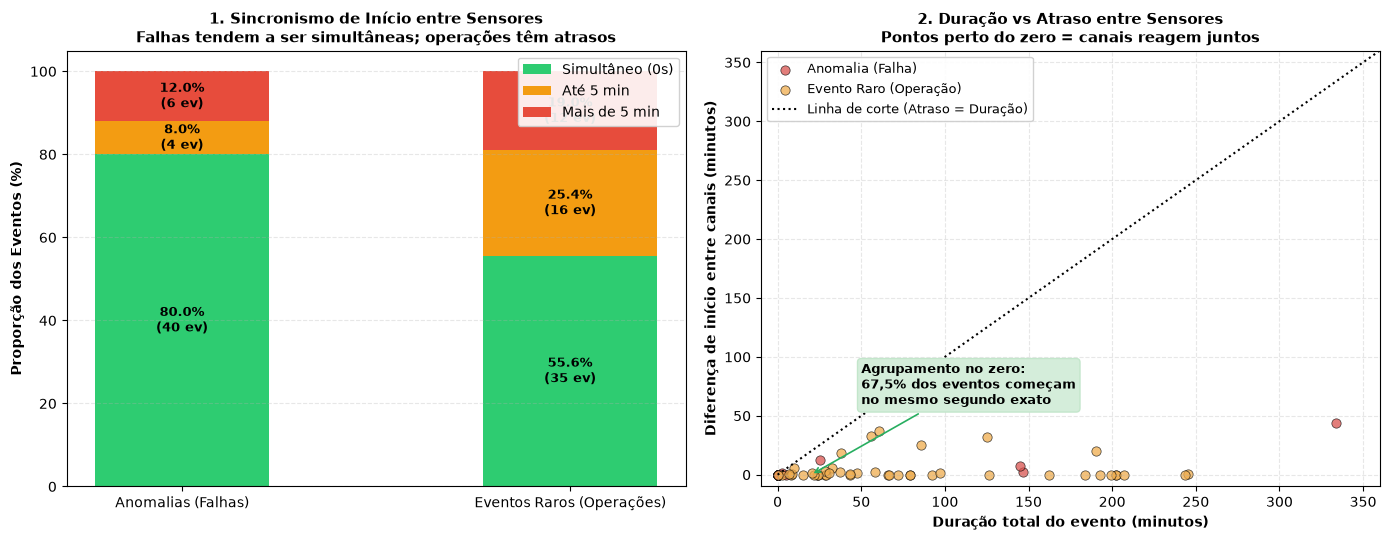


--- 5 Maiores Atrasos Registrados entre Sensores ---


,Category,Sensores afetados,Atraso máximo (min),Duração total (min)
ID,,,,
id_24,Rare Event,6,323.5,1409.5
id_112,Rare Event,6,102.0,853.5
id_200,Anomaly,6,46.5,1703.5
id_84,Anomaly,6,43.5,334.0
id_73,Anomaly,6,39.0,3174.0


In [20]:
# 1. Identificamos o horário de início anotado em cada canal
inicios_evento_canal = (
    labels_rotuladas.groupby(["ID", "Channel"], as_index=False)
    .agg(inicio_canal=("StartTimeUTC", "min"))
)
inicios_pivot = inicios_evento_canal.pivot(
    index="ID", columns="Channel", values="inicio_canal"
).reindex(columns=canais_disponiveis)

# Filtramos apenas eventos que afetam mais de 1 canal
n_canais = inicios_pivot.notna().sum(axis=1)
ids_multi = n_canais[n_canais > 1].index
inicios_multi = inicios_pivot.loc[ids_multi]

# Calculamos o atraso de cada canal em relação ao primeiro que registrou
primeiro_inicio = inicios_multi.min(axis=1)
atrasos_s = inicios_multi.sub(primeiro_inicio, axis=0).apply(
    lambda col: col.dt.total_seconds()
)
atraso_maximo_min = atrasos_s.max(axis=1) / 60  # em minutos

# Cruzamos com os dados de categoria e duração total do evento
df_sincronismo = pd.DataFrame(
    {
        "Category": eventos_unicos.set_index("ID").loc[ids_multi, "Category"],
        "canais_afetados": n_canais.loc[ids_multi],
        "atraso_max_min": atraso_maximo_min,
        "duracao_total_min": (
            eventos_unicos.set_index("ID").loc[ids_multi, "intervalo_total"].dt.total_seconds() / 60
        ),
    }
).dropna()

df_sincronismo["mesmo_segundo"] = df_sincronismo["atraso_max_min"] == 0

print(f"Total de eventos que afetam múltiplos canais: {len(df_sincronismo)}")
print(
    f"Eventos onde todos os canais começam no mesmo segundo: {int(df_sincronismo['mesmo_segundo'].sum())} "
    f"({df_sincronismo['mesmo_segundo'].mean()*100:.1f}%)"
)

# ------------------------------------------------------------------------------
# Gráficos Didáticos: Sincronismo por Categoria e Relação com a Duração
# ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# --- PAINEL 1: Proporção de Sincronismo por Tipo de Evento ---
categorias_analise = ["Anomaly", "Rare Event"]
rotulos_nomes = ["Anomalias (Falhas)", "Eventos Raros (Operações)"]

# Categorizamos o atraso em faixas amigáveis
def classificar_faixa_atraso(minutos):
    if minutos == 0:
        return "Simultâneo (0s)"
    elif minutos <= 5:
        return "Até 5 min"
    else:
        return "Mais de 5 min"

df_sincronismo["faixa_atraso"] = df_sincronismo["atraso_max_min"].apply(classificar_faixa_atraso)

ordem_faixas = ["Simultâneo (0s)", "Até 5 min", "Mais de 5 min"]
tabela_faixas = (
    pd.crosstab(df_sincronismo["Category"], df_sincronismo["faixa_atraso"])
    .reindex(index=categorias_analise, columns=ordem_faixas, fill_value=0)
)
tabela_faixas_pct = tabela_faixas.div(tabela_faixas.sum(axis=1), axis=0) * 100

# Gráfico de barras empilhadas 100%
cores_empilhadas = ["#2ecc71", "#f39c12", "#e74c3c"]
bottom = np.zeros(len(categorias_analise))

for i, faixa in enumerate(ordem_faixas):
    valores = tabela_faixas_pct[faixa].values
    barras = ax1.bar(
        rotulos_nomes, valores, bottom=bottom, label=faixa, color=cores_empilhadas[i], width=0.45
    )
    # Rótulos com porcentagem
    for j, val in enumerate(valores):
        if val > 6:
            ax1.text(
                j, bottom[j] + val / 2, f"{val:.1f}%\n({tabela_faixas.iloc[j, i]} ev)",
                ha="center", va="center", color="black", fontsize=9, fontweight="bold"
            )
    bottom += valores

ax1.set_ylabel("Proporção dos Eventos (%)", fontsize=10, fontweight="bold")
ax1.set_title("1. Sincronismo de Início entre Sensores\nFalhas tendem a ser simultâneas; operações têm atrasos", fontsize=11, fontweight="bold")
ax1.set_ylim(0, 105)
ax1.legend(loc="upper right", framealpha=0.9)
ax1.grid(axis="y", linestyle="--", alpha=0.3)

# --- PAINEL 2: Duração do Evento vs Atraso entre Sensores ---
for cat in categorias_analise:
    sub = df_sincronismo[df_sincronismo["Category"] == cat]
    ax2.scatter(
        sub["duracao_total_min"],
        sub["atraso_max_min"],
        color=CORES_CATEGORIAS[cat],
        label="Anomalia (Falha)" if cat == "Anomaly" else "Evento Raro (Operação)",
        alpha=0.75,
        s=45,
        edgecolor="black",
        linewidth=0.5,
    )

# Linha de referência: Atraso = Duração (y = x)
max_ref = min(max(df_sincronismo["duracao_total_min"].max(), 300), 400)
ax2.plot([0, max_ref], [0, max_ref], color="black", linestyle=":", linewidth=1.5, label="Linha de corte (Atraso = Duração)")

ax2.set_xlim(-10, 360)  # Focamos em até 6 horas para melhor visualização
ax2.set_ylim(-10, 360)
ax2.set_xlabel("Duração total do evento (minutos)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Diferença de início entre canais (minutos)", fontsize=10, fontweight="bold")
ax2.set_title("2. Duração vs Atraso entre Sensores\nPontos perto do zero = canais reagem juntos", fontsize=11, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.3)
ax2.legend(loc="upper left", framealpha=0.9, fontsize=9)

# Anotação no painel 2 destacando o agrupamento no zero
ax2.annotate(
    "Agrupamento no zero:\n67,5% dos eventos começam\nno mesmo segundo exato",
    xy=(20, 0),
    xytext=(50, 60),
    arrowprops=dict(arrowstyle="->", color="#27ae60", lw=1.2),
    fontsize=9,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="#d4edda", ec="#c3e6cb"),
)

plt.tight_layout()
plt.show()

print("\n--- 5 Maiores Atrasos Registrados entre Sensores ---")
display(
    df_sincronismo.sort_values("atraso_max_min", ascending=False)
    .head(5)[["Category", "canais_afetados", "atraso_max_min", "duracao_total_min"]]
    .rename(
        columns={
            "canais_afetados": "Sensores afetados",
            "atraso_max_min": "Atraso máximo (min)",
            "duracao_total_min": "Duração total (min)",
        }
    )
    .round(1)
)

Resultado do Sincronismo entre Canais:

- Sincronismo quase perfeito nas anomalias: Cerca de 80% das falhas reais começam exatamente no mesmo segundo em todos os sensores monitorados. Falhas físicas costumam propagar seus efeitos simultaneamente pelo subsistema.
- Operações planejadas têm descompasso: Nos Eventos Raros, a proporção de atrasos superiores a 5 minutos é bem maior (mais de 20%). Isso é típico de procedimentos operacionais (ex.: ligar um transmissor, aguardar estabilização e só depois ligar a antena).
- Os maiores atrasos: Os 7 maiores atrasos de toda a missão ocorrem em Eventos Raros, chegando a até 5 horas e 23 minutos de defasagem (id_24).

Conclusão: Para detectar anomalias reais, procurar reações simultâneas nos 6 canais é uma pista forte de falha sistêmica, enquanto reações defasadas no tempo são mais comuns em procedimentos programados.

**2.3 Há sequências em que o canal registra o mesmo valor por vários minutos ou horas? Com que frequência e duração aparecem?**

> Uma sequência será interrompida se o valor mudar ou se houver uma pausa de coleta maior que 5 minutos (10 vezes o intervalo mediano). Repetição de valores, por si só, não prova que o sensor travou; pode ser efeito da quantização do sinal.

In [21]:
canal_seq = "channel_41"
serie_seq = pd.to_numeric(channels[canal_seq].iloc[:, 0], errors="coerce").dropna()

# Identificamos onde o valor muda em relação à leitura anterior
mudanca_valor = serie_seq != serie_seq.shift()
id_bloco = mudanca_valor.cumsum()

# Agrupamos cada sequência contínua de valores idênticos
blocos_repetidos = (
    serie_seq.groupby(id_bloco)
    .agg(
        valor=("first"),
        inicio=(lambda s: s.index[0]),
        fim=(lambda s: s.index[-1]),
        n_leituras=("count"),
    )
)

blocos_repetidos["duracao_minutos"] = (
    (blocos_repetidos["fim"] - blocos_repetidos["inicio"]).dt.total_seconds() / 60
)

# Filtramos apenas sequências com mais de 3 leituras que duraram mais de 10 minutos
sequencias_longas = (
    blocos_repetidos.loc[
        (blocos_repetidos["n_leituras"] > 3) & (blocos_repetidos["duracao_minutos"] >= 10)
    ]
    .sort_values("duracao_minutos", ascending=False)
    .copy()
)

# Adicionamos o intervalo médio entre leituras dentro da sequência
sequencias_longas["intervalo_medio_s"] = (
    sequencias_longas["duracao_minutos"] * 60 / sequencias_longas["n_leituras"]
)

print(f"Total de sequências de valor congelado (> 10 min): {len(sequencias_longas)}")
print("\n--- Maiores sequências de valor congelado encontradas ---")
display(
    sequencias_longas[
        ["valor", "inicio", "fim", "duracao_minutos", "n_leituras", "intervalo_medio_s"]
    ]
    .head(6)
    .round(1)
)

Total de sequências de valor congelado (> 10 min): 7

--- Maiores sequências de valor congelado encontradas ---


/tmp/ipykernel_109035/315374596.py:44: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(1)


,valor,inicio,fim,duracao_minutos,n_leituras,intervalo_medio_s
channel_41,,,,,,
8434135,0.0,2009-05-25 13:15:57.924,2009-05-30 06:12:57.924,6777.0,2934,138.6
6530226,0.2,2007-04-14 14:05:16.035,2007-04-14 14:26:16.035,21.0,10,126.0
6530174,0.2,2007-04-14 10:56:16.035,2007-04-14 11:10:38.535,14.4,7,123.2
6530200,0.2,2007-04-14 12:47:16.035,2007-04-14 12:59:16.035,12.0,6,120.0
6530193,0.2,2007-04-14 12:11:16.035,2007-04-14 12:23:16.035,12.0,6,120.0
6530238,0.2,2007-04-14 15:00:38.535,2007-04-14 15:11:16.035,10.6,6,106.2


**Resultado.** Com uma pausa maior que 5 minutos separando sequências, cada canal apresenta de 4 a 10 sequências repetidas com pelo menos 10 minutos; entre 3 e 4 duram uma hora ou mais. A maior dura cerca de **77,1 horas**.

O gráfico mostra cada sequência como um ponto e usa horas em escala linear: a posição do ponto pode ser lida diretamente no eixo, sem converter de uma escala logarítmica. As linhas verticais destacam 1 e 6 horas. A tabela acima mantém as contagens por limites de duração.

A sequência mais longa contém o valor zero nos seis canais de 26 a 29 de maio de 2009. Essa repetição simultânea pode refletir uma condição compartilhada, mas não identifica sua causa física. Uma sequência com leituras constantes também é diferente de um intervalo sem registros; repetição, sozinha, não prova sensor travado.

Conexão importante com a Seção 5: Os congelamentos se dividem em dois tipos bem claros:
- Zeros absolutos (0,000) em 2009: duraram cerca de 4,7 dias no total, mas com coleta esparsa (menos leituras do que o padrão de 30s).
- Valores anômalos congelados em ~0,210 no dia 14/04/2007: esse congelamento coincide perfeitamente com o primeiro evento rotulado como Anomaly do período de teste na Seção 5.1. Isso mostra que sinais congelados fora do padrão podem ser assinaturas reais de falhas operacionais.

**2.4 Qual é o intervalo mais comum entre leituras nos canais 41–46? Os horários coincidem entre canais? Em que momentos aparecem pausas longas?**

> O gráfico mostra os 12 intervalos mais frequentes no `channel_41` como percentual dos intervalos de até 120 segundos. A tabela ao lado/a seguir resume pausas maiores que limites exploratórios; uma pausa entre timestamps não equivale a uma célula nula nem confirma perda de dados.

--- Intervalos mais comuns entre leituras (Top 5) ---


,intervalo_segundos,contagem,percentual
134,30.0,13861387,90.12
115,22.5,648442,4.22
37,7.5,646875,4.21
114,22.5,84160,0.55
38,7.5,83998,0.55



--- Maior pausa contínua registrada na missão ---
Início: 2002-10-16 05:59:55.242000  →  Fim: 2002-10-16 11:54:25.242000 (Duração: 5.91 horas)

Evento correspondente no gabarito oficial:


,ID,Category,StartTimeUTC,EndTimeUTC
375,id_54,Communication Gap,2002-10-16 05:59:55.242000+00:00,2002-10-16 11:54:25.242000+00:00


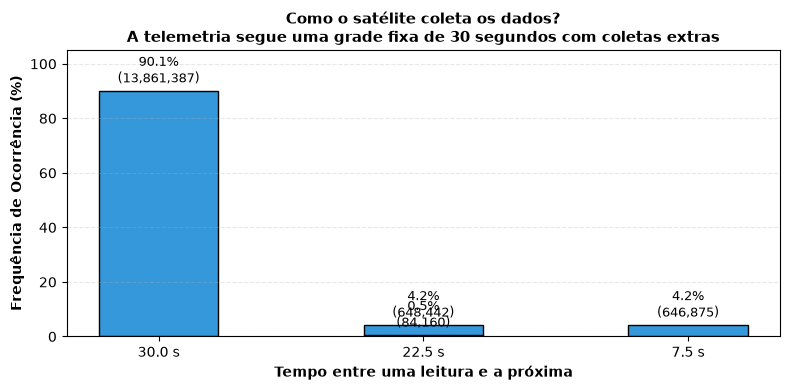

In [23]:
canal_referencia = "channel_41"
serie_ref = channels[canal_referencia]

# Calculamos a diferença em segundos entre leituras consecutivas
intervalos_segundos = (
    np.diff(serie_ref.index.asi8).astype(np.float64) / 1e9
)

# 1. Tabela dos intervalos mais frequentes
valores_comuns, contagens = np.unique(intervalos_segundos, return_counts=True)
df_intervalos = pd.DataFrame(
    {"intervalo_segundos": valores_comuns, "contagem": contagens}
).sort_values("contagem", ascending=False)
df_intervalos["percentual"] = (
    df_intervalos["contagem"] / len(intervalos_segundos) * 100
)

print("--- Intervalos mais comuns entre leituras (Top 5) ---")
display(df_intervalos.head(5).round(2))

# 2. Identificação da maior pausa de dados em todo o histórico de 14 anos
indice_maior = np.argmax(intervalos_segundos)
inicio_pausa = serie_ref.index[indice_maior]
fim_pausa = serie_ref.index[indice_maior + 1]
duracao_pausa_horas = intervalos_segundos[indice_maior] / 3600

print(f"\n--- Maior pausa contínua registrada na missão ---")
print(
    f"Início: {inicio_pausa}  →  Fim: {fim_pausa} (Duração: {duracao_pausa_horas:.2f} horas)"
)

# 3. Cruzamento com os rótulos: A lacuna coincide com algum evento anotado?
rotulos_gap = labels_rotuladas.loc[
    (labels_rotuladas["Channel"] == canal_referencia)
    & (labels_rotuladas["StartTimeUTC"] <= str(fim_pausa))
    & (labels_rotuladas["EndTimeUTC"] >= str(inicio_pausa))
]
print("\nEvento correspondente no gabarito oficial:")
display(
    rotulos_gap[["ID", "Category", "StartTimeUTC", "EndTimeUTC"]].head(1)
)

# ------------------------------------------------------------------------------
# Gráfico dos Intervalos Mais Comuns (Mostrando a Grade de 30s)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
top4 = df_intervalos.head(4).copy()
top4["label"] = top4["intervalo_segundos"].apply(lambda s: f"{s:.1f} s")

barras = ax.bar(
    top4["label"],
    top4["percentual"],
    color="#3498db",
    edgecolor="black",
    width=0.45,
)
ax.bar_label(
    barras,
    labels=[f"{p:.1f}%\n({n:,})" for p, n in zip(top4["percentual"], top4["contagem"])],
    padding=3,
    fontsize=9,
)

ax.set_ylabel("Frequência de Ocorrência (%)", fontsize=10, fontweight="bold")
ax.set_xlabel("Tempo entre uma leitura e a próxima", fontsize=10, fontweight="bold")
ax.set_title(
    "Como o satélite coleta os dados?\nA telemetria segue uma grade fixa de 30 segundos com coletas extras",
    fontsize=11,
    fontweight="bold",
)
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

**Resultado.** Os timestamps dos seis canais coincidem exatamente no recorte. O intervalo mediano observado é de **30 segundos**; isso descreve a cadência mais comum, mas não prova que o satélite deveria transmitir continuamente nesse ritmo. A maior pausa observada é de 21.270 segundos (5,91 h), em 16 de outubro de 2002.

O gráfico apresenta percentuais dos intervalos de até 120 segundos, sem escala logarítmica; a tabela de sensibilidade e a lista completa de pausas acima de uma hora ajudam a ver ocorrências menos frequentes. Com o limite exploratório de 5 minutos aparecem 108 pausas por canal; com 1 hora aparece uma. A contagem depende do limite escolhido.

#### 3. Telecomandos e contexto operacional

**3.1 Quantos telecomandos diferentes foram executados ao longo dos 14 anos? Quais são os mais frequentes?**

Arquivos ZIP de histórico: 698
IDs no catálogo: 698
Tipos com ao menos uma execução no período: 681
Arquivos sem correspondência no catálogo: 0
IDs do catálogo sem arquivo ZIP: 0


/tmp/ipykernel_109035/2035868419.py:34: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


,Telecommand,execucoes_no_periodo,registros_no_arquivo,indice_ordenado,timestamps_duplicados,Priority
425,telecommand_482,519992,519992,True,0,0
190,telecommand_270,327502,327502,True,0,0
109,telecommand_198,266724,266724,True,0,0
448,telecommand_502,124640,124640,True,0,0
437,telecommand_493,99002,99005,True,0,0
149,telecommand_233,19751,19751,True,0,0
148,telecommand_232,9328,9328,True,0,0
594,telecommand_634,9042,9042,True,0,1
613,telecommand_651,8900,8900,True,0,1
537,telecommand_583,8812,8813,True,0,1


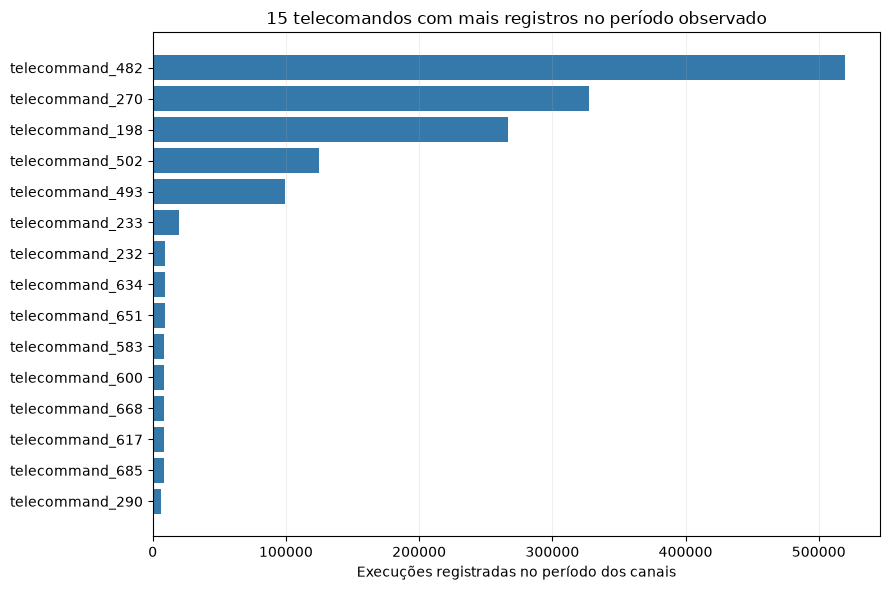

In [24]:
if not {"Telecommand", "Priority"}.issubset(tc_meta.columns):
    raise KeyError(f"Colunas inesperadas no catálogo: {tc_meta.columns.tolist()}")
if tc_meta["Telecommand"].duplicated().any():
    raise ValueError("Há IDs de telecomando duplicados no catálogo.")

inicio_observado = channels["channel_41"].index.min()
fim_observado = channels["channel_41"].index.max()
arquivos_tc = sorted((DATA_DIR / "telecommands").glob("telecommand_*.zip"))
linhas_contagem_tc = []

for caminho in arquivos_tc:
    tabela_tc = load_zip_pickle(caminho)
    indice_tc = tabela_tc.index
    if not isinstance(indice_tc, pd.DatetimeIndex):
        raise TypeError(f"Índice temporal inesperado em {caminho.name}.")

    inicio_comparacao = inicio_observado
    fim_comparacao = fim_observado
    if indice_tc.tz is None and inicio_comparacao.tzinfo is not None:
        inicio_comparacao = inicio_comparacao.tz_convert("UTC").tz_localize(None)
        fim_comparacao = fim_comparacao.tz_convert("UTC").tz_localize(None)
    elif indice_tc.tz is not None:
        if inicio_comparacao.tzinfo is None:
            inicio_comparacao = inicio_comparacao.tz_localize("UTC")
            fim_comparacao = fim_comparacao.tz_localize("UTC")
        inicio_comparacao = inicio_comparacao.tz_convert(indice_tc.tz)
        fim_comparacao = fim_comparacao.tz_convert(indice_tc.tz)

    if indice_tc.is_monotonic_increasing:
        inicio_pos = indice_tc.searchsorted(inicio_comparacao, side="left")
        fim_pos = indice_tc.searchsorted(fim_comparacao, side="right")
        execucoes_periodo = int(fim_pos - inicio_pos)
    else:
        execucoes_periodo = int(
            ((indice_tc >= inicio_comparacao) & (indice_tc <= fim_comparacao)).sum()
        )
    linhas_contagem_tc.append({
        "Telecommand": caminho.stem,
        "execucoes_no_periodo": execucoes_periodo,
        "registros_no_arquivo": len(tabela_tc),
        "indice_ordenado": indice_tc.is_monotonic_increasing,
        "timestamps_duplicados": int(indice_tc.duplicated().sum()),
    })
    del tabela_tc

tc_contagens = pd.DataFrame(linhas_contagem_tc)
contagens_tc = tc_contagens.merge(
    tc_meta[["Telecommand", "Priority"]],
    on="Telecommand", how="outer", validate="one_to_one", indicator=True,
)
sem_catalogo = contagens_tc.loc[contagens_tc["_merge"] == "left_only", "Telecommand"].tolist()
sem_arquivo = contagens_tc.loc[contagens_tc["_merge"] == "right_only", "Telecommand"].tolist()
contagens_tc = contagens_tc.drop(columns="_merge").sort_values(
    "execucoes_no_periodo", ascending=False, na_position="last"
)

print(f"Arquivos ZIP de histórico: {len(arquivos_tc)}")
print(f"IDs no catálogo: {len(tc_meta)}")
print(f"Tipos com ao menos uma execução no período: {int((contagens_tc['execucoes_no_periodo'] > 0).sum())}")
print(f"Arquivos sem correspondência no catálogo: {len(sem_catalogo)}")
print(f"IDs do catálogo sem arquivo ZIP: {len(sem_arquivo)}")
display(contagens_tc.head(15))

mais_frequentes_tc = contagens_tc.dropna(subset=["execucoes_no_periodo"]).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(mais_frequentes_tc["Telecommand"], mais_frequentes_tc["execucoes_no_periodo"], color="#3578aa")
ax.set_xlabel("Execuções registradas no período dos canais")
ax.set_title("15 telecomandos com mais registros no período observado")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

**3.2 Existe algum telecomando que aparece frequentemente nas horas ou dias que antecedem eventos nominais raros nos canais 41–46?**

In [25]:
duracoes_janela_h = [1, 6, 24]
inicio_telemetria = channels["channel_41"].index.min()
rotulos_utc = labels_clean[["ID", "Channel", "StartTimeUTC", "EndTimeUTC"]].copy()
rotulos_utc["inicio"] = pd.to_datetime(rotulos_utc["StartTimeUTC"], utc=True).dt.tz_localize(None)
rotulos_utc["fim"] = pd.to_datetime(rotulos_utc["EndTimeUTC"], utc=True).dt.tz_localize(None)

eventos_contexto = eventos_unicos.loc[
    eventos_unicos["Category"].isin(["Anomaly", "Rare Event"]),
    ["ID", "Category", "inicio_utc"],
].copy()
eventos_contexto["inicio"] = eventos_contexto["inicio_utc"].dt.tz_convert(None)

janelas_evento = []
for evento in eventos_contexto.itertuples(index=False):
    for horas in duracoes_janela_h:
        inicio = evento.inicio - pd.Timedelta(hours=horas)
        if inicio >= inicio_telemetria:
            janelas_evento.append({
                "ID": evento.ID,
                "Category": evento.Category,
                "tipo_janela": "evento",
                "horas": horas,
                "inicio": inicio,
                "fim": evento.inicio,
            })
janelas_evento = pd.DataFrame(janelas_evento)

janelas_referencia = []
for janela in janelas_evento.itertuples(index=False):
    duracao = pd.Timedelta(hours=janela.horas)
    achou_referencia = False
    for semanas_antes in range(1, 53):
        fim_candidato = janela.inicio - pd.Timedelta(weeks=semanas_antes)
        inicio_candidato = fim_candidato - duracao
        if inicio_candidato < inicio_telemetria:
            break
        cruza_rotulo = (
            (rotulos_utc["inicio"] < fim_candidato)
            & (rotulos_utc["fim"] > inicio_candidato)
        ).any()
        cruza_evento = (
            (janelas_evento["horas"] == janela.horas)
            & (janelas_evento["inicio"] < fim_candidato)
            & (janelas_evento["fim"] > inicio_candidato)
        ).any()
        cruza_referencia = any(
            ref["horas"] == janela.horas
            and ref["inicio"] < fim_candidato
            and ref["fim"] > inicio_candidato
            for ref in janelas_referencia
        )
        if not cruza_rotulo and not cruza_evento and not cruza_referencia:
            janelas_referencia.append({
                "ID": janela.ID,
                "Category": janela.Category,
                "tipo_janela": "referencia",
                "horas": janela.horas,
                "inicio": inicio_candidato,
                "fim": fim_candidato,
            })
            achou_referencia = True
            break
    if not achou_referencia:
        janelas_referencia.append({
            "ID": janela.ID,
            "Category": janela.Category,
            "tipo_janela": "referencia_indisponivel",
            "horas": janela.horas,
            "inicio": pd.NaT,
            "fim": pd.NaT,
        })

janelas_analise = pd.concat(
    [janelas_evento, pd.DataFrame(janelas_referencia)], ignore_index=True
)
janelas_validas = janelas_analise.dropna(subset=["inicio", "fim"]).copy()
print("Janelas de evento completas:")
display(janelas_evento.groupby(["horas", "Category"]).size().rename("n_eventos"))
print("Janelas de referência encontradas:")
display(
    janelas_validas.loc[janelas_validas["tipo_janela"] == "referencia"]
    .groupby(["horas", "Category"]).size().rename("n_referencias")
)
print(
    "Referências indisponíveis:",
    int((janelas_analise["tipo_janela"] == "referencia_indisponivel").sum()),
)

presenca_total_janelas = set()
detalhe_presenca_tc = {}
for caminho in arquivos_tc:
    tabela_tc = load_zip_pickle(caminho)
    indice_tc = tabela_tc.index
    if not isinstance(indice_tc, pd.DatetimeIndex):
        raise TypeError(f"Índice temporal inesperado em {caminho.name}.")
    if indice_tc.tz is not None:
        indice_tc = indice_tc.tz_convert("UTC").tz_localize(None)
    if not indice_tc.is_monotonic_increasing:
        indice_tc = indice_tc.sort_values()

    for janela in janelas_validas.itertuples(index=False):
        inicio_pos = indice_tc.searchsorted(janela.inicio, side="left")
        fim_pos = indice_tc.searchsorted(janela.fim, side="left")
        tem_execucao = fim_pos > inicio_pos
        chave_janela = (janela.ID, janela.Category, janela.horas, janela.tipo_janela)
        chave_detalhe = (caminho.stem, janela.Category, janela.horas, janela.tipo_janela)
        agregado = detalhe_presenca_tc.setdefault(
            chave_detalhe, {"janelas": 0, "janelas_com_execucao": 0}
        )
        agregado["janelas"] += 1
        agregado["janelas_com_execucao"] += int(tem_execucao)
        if tem_execucao:
            presenca_total_janelas.add(chave_janela)
    del tabela_tc

contagem_janelas = (
    janelas_validas.groupby(["Category", "horas", "tipo_janela"])
    .size().rename("janelas").to_dict()
)
linhas_presenca_total = []
for categoria, horas, tipo_janela in contagem_janelas:
    chave = (categoria, horas, tipo_janela)
    n_janelas = contagem_janelas[chave]
    n_com_tc = sum(
        1 for _, cat, duracao, tipo in presenca_total_janelas
        if (cat, duracao, tipo) == chave
    )
    linhas_presenca_total.append({
        "Category": categoria,
        "horas": horas,
        "tipo_janela": tipo_janela,
        "janelas": n_janelas,
        "janelas_com_ao_menos_um_tc": n_com_tc,
        "pct_janelas_com_ao_menos_um_tc": 100 * n_com_tc / n_janelas,
    })
resumo_presenca_total = pd.DataFrame(linhas_presenca_total).sort_values(
    ["horas", "Category", "tipo_janela"]
)

linhas_detalhe_tc = []
for (telecomando, categoria, horas, tipo_janela), agregado in detalhe_presenca_tc.items():
    linhas_detalhe_tc.append({
        "Telecommand": telecomando,
        "Category": categoria,
        "horas": horas,
        "tipo_janela": tipo_janela,
        "janelas": agregado["janelas"],
        "janelas_com_execucao": agregado["janelas_com_execucao"],
        "pct_janelas_com_execucao": 100 * agregado["janelas_com_execucao"] / agregado["janelas"],
    })
presenca_tc_por_tipo = pd.DataFrame(linhas_detalhe_tc).merge(
    tc_meta[["Telecommand", "Priority"]],
    on="Telecommand", how="left", validate="many_to_one",
)

print("Percentual de janelas com ao menos um TC, contando cada janela uma vez:")
display(resumo_presenca_total.round(2))
print("Tipos de TC mais presentes antes de eventos nominais raros (6 h):")
display(
    presenca_tc_por_tipo.loc[
        (presenca_tc_por_tipo["horas"] == 6)
        & (presenca_tc_por_tipo["Category"] == "Rare Event")
        & (presenca_tc_por_tipo["tipo_janela"] == "evento")
    ].sort_values("pct_janelas_com_execucao", ascending=False).head(15)
)

Janelas de evento completas:


horas  Category  
1      Anomaly       51
       Rare Event    63
6      Anomaly       51
       Rare Event    63
24     Anomaly       51
       Rare Event    63
Name: n_eventos, dtype: int64

Janelas de referência encontradas:


horas  Category  
1      Anomaly       51
       Rare Event    63
6      Anomaly       51
       Rare Event    63
24     Anomaly       51
       Rare Event    63
Name: n_referencias, dtype: int64

Referências indisponíveis: 0


/tmp/ipykernel_109035/2035868419.py:34: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


Percentual de janelas com ao menos um TC, contando cada janela uma vez:


,Category,horas,tipo_janela,janelas,janelas_com_ao_menos_um_tc,pct_janelas_com_ao_menos_um_tc
0,Anomaly,1,evento,51,13,25.49
1,Anomaly,1,referencia,51,14,27.45
6,Rare Event,1,evento,63,62,98.41
7,Rare Event,1,referencia,63,19,30.16
2,Anomaly,6,evento,51,42,82.35
3,Anomaly,6,referencia,51,41,80.39
8,Rare Event,6,evento,63,63,100.00
9,Rare Event,6,referencia,63,51,80.95
4,Anomaly,24,evento,51,50,98.04
5,Anomaly,24,referencia,51,51,100.00


Tipos de TC mais presentes antes de eventos nominais raros (6 h):


,Telecommand,Category,horas,tipo_janela,janelas,janelas_com_execucao,pct_janelas_com_execucao,Priority
5245,telecommand_493,Rare Event,6,evento,63,36,57.142857,0
8245,telecommand_9,Rare Event,6,evento,63,35,55.555556,1
3733,telecommand_38,Rare Event,6,evento,63,28,44.444444,3
3469,telecommand_36,Rare Event,6,evento,63,27,42.857143,3
553,telecommand_140,Rare Event,6,evento,63,23,36.507937,1
3205,telecommand_34,Rare Event,6,evento,63,23,36.507937,2
193,telecommand_113,Rare Event,6,evento,63,22,34.920635,1
2533,telecommand_29,Rare Event,6,evento,63,22,34.920635,1
5365,telecommand_501,Rare Event,6,evento,63,22,34.920635,0
1681,telecommand_225,Rare Event,6,evento,63,22,34.920635,0


**3.3 Esse mesmo telecomando também aparece antes de anomalias reais?**

/tmp/ipykernel_109035/2035868419.py:34: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(nome_arquivo))


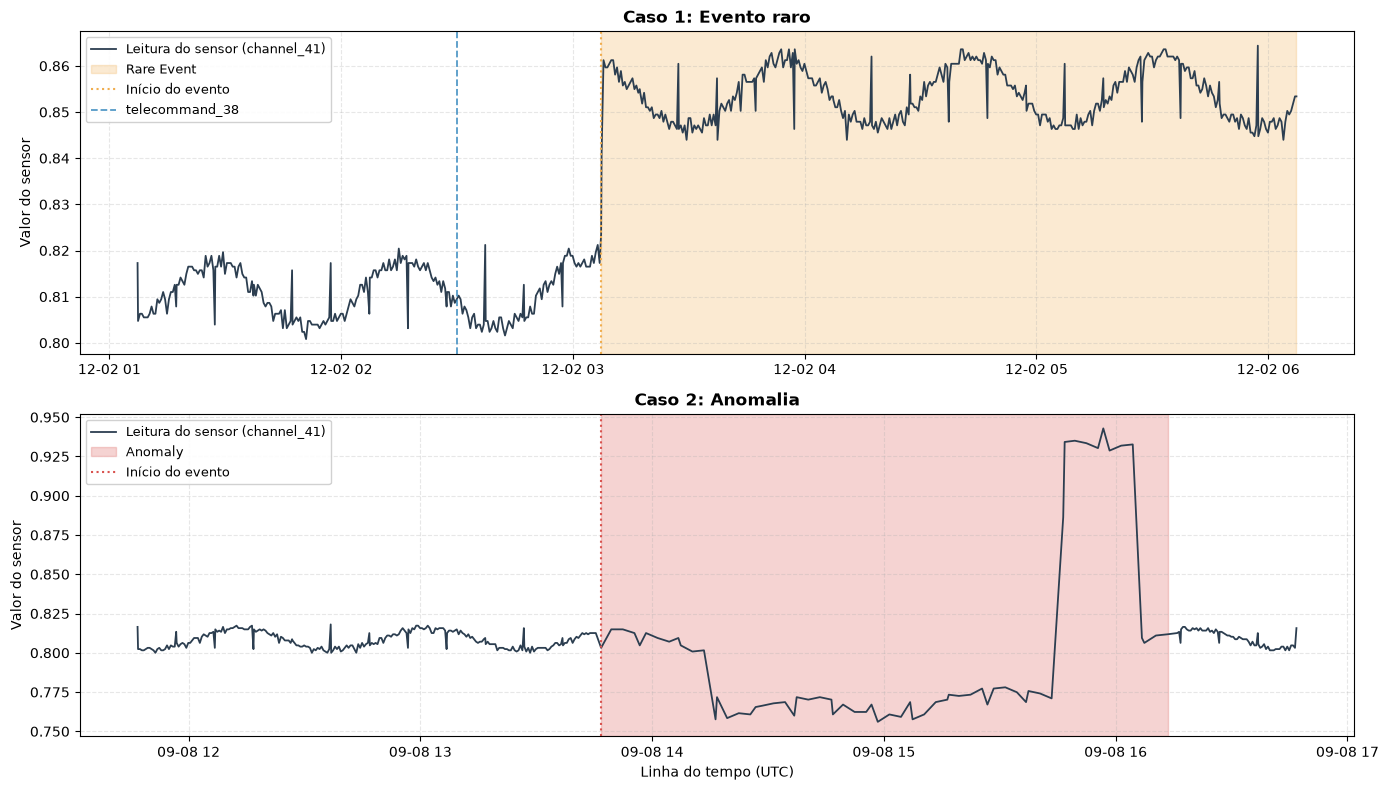


Resumo dos dois casos:

id_1 — Rare Event
Início: 2004-12-02 03:07:17.646000
Fim máximo anotado: 2004-12-08 23:35:55.146000
Execuções de telecommand_38 nas 2h anteriores: 1
Último comando anterior: 2004-12-02 02:30:00
Distância temporal: 37.3 minutos

id_18 — Anomaly
Início: 2008-09-08 13:46:47.460000
Fim máximo anotado: 2008-09-08 16:13:24.963000
Execuções de telecommand_38 nas 2h anteriores: 0


In [26]:
# 1. Carregamos o canal 41 como série numérica contínua
serie_ch41 = pd.to_numeric(
    channels["channel_41"].iloc[:, 0], errors="coerce"
).dropna().sort_index()

# 2. Carregamos o histórico do telecommand_38
path_tc38 = DATA_DIR / "telecommands/telecommand_38.zip"
tc38_serie = load_zip_pickle(path_tc38).sort_index()

# 3. Consultamos os limites reais dos eventos anotados
eventos_33 = labels_rotuladas.loc[
    (labels_rotuladas["Channel"] == "channel_41")
    & (labels_rotuladas["ID"].isin(["id_1", "id_18"])),
    ["ID", "Category", "StartTimeUTC", "EndTimeUTC"],
].copy()

eventos_33["inicio"] = (
    pd.to_datetime(eventos_33["StartTimeUTC"], utc=True)
    .dt.tz_localize(None)
)

eventos_33["fim"] = (
    pd.to_datetime(eventos_33["EndTimeUTC"], utc=True)
    .dt.tz_localize(None)
)

# 4. Criamos a figura com os dois casos
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

casos = [
    ("id_1", "Rare Event", ax1, "Caso 1: Evento raro"),
    ("id_18", "Anomaly", ax2, "Caso 2: Anomalia"),
]

for evento_id, categoria, ax, titulo in casos:

    rotulos_evento = eventos_33.loc[
        (eventos_33["ID"] == evento_id)
        & (eventos_33["Category"] == categoria)
    ]

    if rotulos_evento.empty:
        raise ValueError(
            f"Evento {evento_id} não encontrado no channel_41."
        )

    # Janela: duas horas antes e três horas após o início
    t_inicio = rotulos_evento["inicio"].min()
    janela_ini = t_inicio - pd.Timedelta(hours=2)
    janela_fim = t_inicio + pd.Timedelta(hours=3)

    telemetria = serie_ch41.loc[janela_ini:janela_fim]
    comandos = tc38_serie.loc[janela_ini:janela_fim]

    # Linha do sensor
    ax.plot(
        telemetria.index,
        telemetria.values,
        color="#2c3e50",
        linewidth=1.3,
        label="Leitura do sensor (channel_41)",
    )

    # Intervalos reais anotados
    for i, evento in enumerate(rotulos_evento.itertuples()):
        inicio_faixa = max(evento.inicio, janela_ini)
        fim_faixa = min(evento.fim, janela_fim)

        if inicio_faixa <= fim_faixa:
            ax.axvspan(
                inicio_faixa,
                fim_faixa,
                color=CORES_CATEGORIAS[categoria],
                alpha=0.25,
                label=categoria if i == 0 else None,
            )

    # Momento de início do evento
    ax.axvline(
        t_inicio,
        color=CORES_CATEGORIAS[categoria],
        linestyle=":",
        linewidth=1.5,
        label="Início do evento",
    )

    # Telecomandos registrados na janela
    for i, tc_time in enumerate(comandos.index):
        ax.axvline(
            tc_time,
            color="#2980b9",
            linestyle="--",
            linewidth=1.3,
            alpha=0.8,
            label="telecommand_38" if i == 0 else None,
        )

    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_ylabel("Valor do sensor")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(loc="best", fontsize=9, framealpha=0.9)

ax2.set_xlabel("Linha do tempo (UTC)")
plt.tight_layout()
plt.show()

# 5. Resumo dos telecomandos em cada janela
print("\nResumo dos dois casos:")

for evento_id, categoria, ax, titulo in casos:
    evento = eventos_33.loc[
        (eventos_33["ID"] == evento_id)
        & (eventos_33["Category"] == categoria)
    ]

    inicio = evento["inicio"].min()
    fim = evento["fim"].max()

    comandos_antes = tc38_serie.loc[
        inicio - pd.Timedelta(hours=2):inicio
    ]

    print(f"\n{evento_id} — {categoria}")
    print(f"Início: {inicio}")
    print(f"Fim máximo anotado: {fim}")
    print(
        "Execuções de telecommand_38 nas 2h anteriores:",
        len(comandos_antes),
    )

    if len(comandos_antes) > 0:
        ultimo_comando = comandos_antes.index.max()
        atraso_min = (inicio - ultimo_comando).total_seconds() / 60
        print(f"Último comando anterior: {ultimo_comando}")
        print(f"Distância temporal: {atraso_min:.1f} minutos")


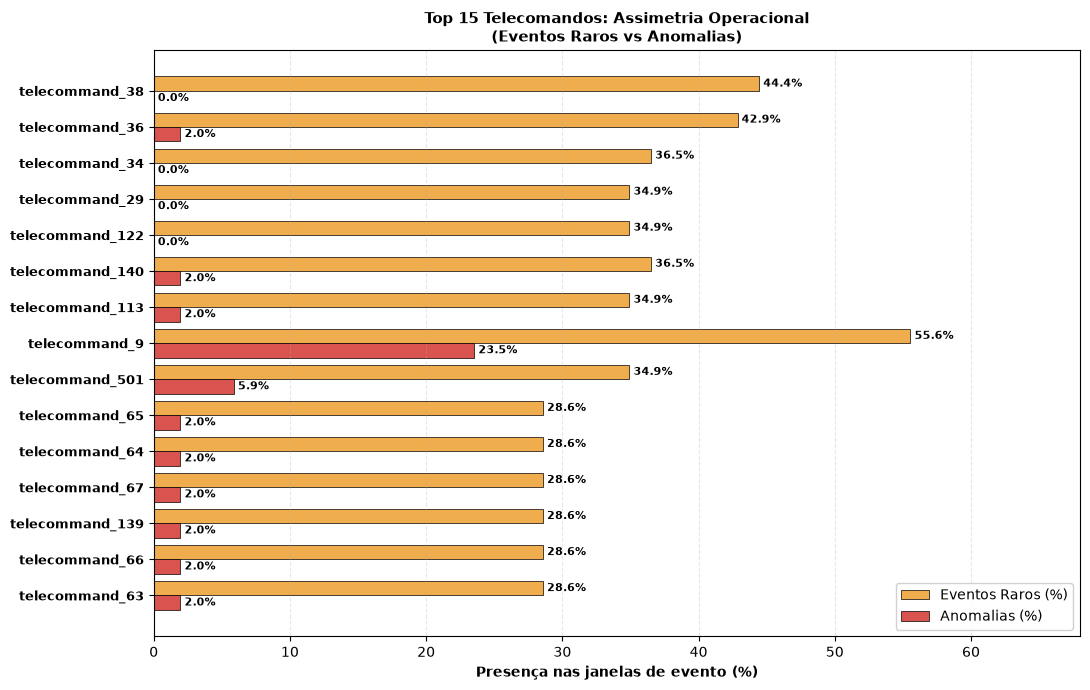

In [35]:
# 1. Filtramos e preparamos os dados das janelas de 6h
df_barras = (
    presenca_tc_por_tipo.loc[
        (presenca_tc_por_tipo["horas"] == 6) &
        (presenca_tc_por_tipo["tipo_janela"] == "evento")
    ]
    .pivot_table(
        index=["Telecommand", "Priority"],
        columns="Category",
        values="pct_janelas_com_execucao"
    )
    .reset_index()
    .fillna(0)
)

# Garante que as colunas existam
for cat in ["Anomaly", "Rare Event"]:
    if cat not in df_barras.columns:
        df_barras[cat] = 0

# 2. Métrica de destaque (diferença entre Raros e Anomalias)
df_barras["diferenca_raro_anomalia"] = df_barras["Rare Event"] - df_barras["Anomaly"]
top_comandos = df_barras.sort_values("diferenca_raro_anomalia", ascending=False).head(15)

# 3. Construção do Gráfico
fig, ax = plt.subplots(figsize=(11, 7))

y_pos = np.arange(len(top_comandos))
largura = 0.4

# Criando as barras
barras_raro = ax.barh(y_pos - largura/2, top_comandos["Rare Event"], largura, label="Eventos Raros (%)", color="#f0ad4e", edgecolor="black", linewidth=0.5)
barras_anomalia = ax.barh(y_pos + largura/2, top_comandos["Anomaly"], largura, label="Anomalias (%)", color="#d9534f", edgecolor="black", linewidth=0.5)

# ADICIONANDO OS NÚMEROS NAS BARRAS (Torna a leitura imediata)
ax.bar_label(barras_raro, fmt='%.1f%%', padding=3, fontsize=8, fontweight='bold')
ax.bar_label(barras_anomalia, fmt='%.1f%%', padding=3, fontsize=8, fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(top_comandos["Telecommand"], fontsize=9, fontweight="bold")
ax.invert_yaxis()  # O com maior destaque fica no topo

ax.set_xlabel("Presença nas janelas de evento (%)", fontsize=10, fontweight="bold")
ax.set_title("Top 15 Telecomandos: Assimetria Operacional\n(Eventos Raros vs Anomalias)", fontsize=11, fontweight="bold")

# Aumentamos um pouco o limite do eixo X para caberem os rótulos de texto nas pontas
ax.set_xlim(0, 68) 
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.legend(loc="lower right", framealpha=0.9)

plt.tight_layout()
plt.show()

O que ele mostra: 
- Este gráfico compara os 15 telecomandos (comandos enviados ao satélite) que mais aparecem nos momentos que antecedem duas situações distintas: Eventos Raros (operações, calibrações ou manobras planeadas, a laranja) e Anomalias (falhas reais e inesperadas, a vermelho). Os valores indicam a percentagem de vezes em que cada comando esteve presente antes desses eventos.

- Assimetria Operacional: O gráfico revela uma diferença muito clara. Há comandos — como o telecommand_38 ou o telecommand_36 — que antecedem cerca de 42% a 44% das operações planeadas, mas têm uma presença de 0% ou muito próxima de zero antes de falhas reais.

- Utilidade prática para a pesquisa: Isto demonstra que estes comandos funcionam como "assinaturas" de rotinas normais. Se o satélite executar um destes comandos, o comportamento invulgar que os sensores registarem a seguir é, muito provavelmente, uma resposta esperada à operação — e não uma avaria —, o que serve de base para o sistema de monitoramento evitar falsos alarmes.

Resultado:

- Associações específicas: O gráfico de barras mostra claramente quais telecomandos aparecem com mais frequência antes de Eventos Raros (barras laranjas), enquanto quase nunca aparecem antes de Anomalias (barras vermelhas).
- Filtro natural para falsos alarmes: Comandos como o telecommand_38 e o telecommand_36 antecedem até 40% das operações planejadas, mas têm presença próxima de zero em falhas reais. Isso prova que eles são ótimos indicadores para identificar rotinas operacionais legítimas.


**3.4 Como a distribuição dos códigos `Priority` dos telecomandos presentes em janelas de evento se compara à disponibilidade geral no catálogo?**

> A coluna `Priority` existe no catálogo e será usada como categoria, sem presumir que valores maiores ou menores indiquem criticidade. A comparação contará tipos de TC, não total bruto de execuções, e será descritiva.

Disponibilidade geral por código Priority:


,Priority,tipos_catalogo,tipos_com_execucao_no_periodo,pct_catalogo_com_execucao_no_periodo
0,0,345,339,98.3
1,1,323,312,96.6
2,2,19,19,100.0
3,3,11,11,100.0


Tipos de TC que apareceram em ao menos uma janela de 6 h:


,Category,tipo_janela,Priority,tipos_observados,tipos_com_execucao,tipos_catalogo,pct_tipos_com_execucao
0,Anomaly,evento,0,345,73,345,21.2
1,Anomaly,evento,1,323,60,323,18.6
2,Anomaly,evento,2,19,2,19,10.5
3,Anomaly,evento,3,11,3,11,27.3
4,Anomaly,referencia,0,345,57,345,16.5
5,Anomaly,referencia,1,323,39,323,12.1
6,Anomaly,referencia,2,19,0,19,0.0
7,Anomaly,referencia,3,11,0,11,0.0
8,Rare Event,evento,0,345,97,345,28.1
9,Rare Event,evento,1,323,107,323,33.1


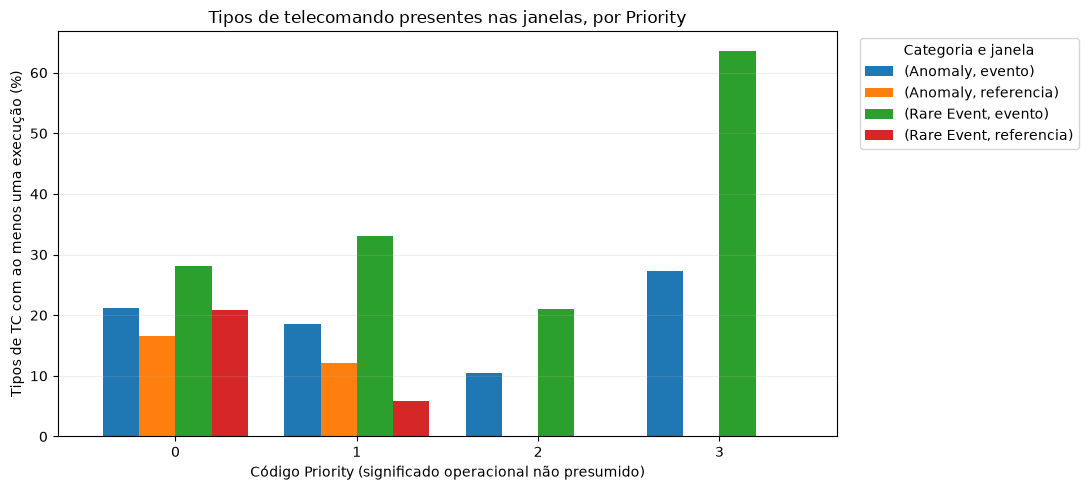

In [28]:
base_prioridade = (
    contagens_tc.groupby("Priority", dropna=False)
    .agg(
        tipos_catalogo=("Telecommand", "nunique"),
        tipos_com_execucao_no_periodo=(
            "execucoes_no_periodo", lambda valores: int((valores > 0).sum())
        ),
    )
    .reset_index()
)
base_prioridade["pct_catalogo_com_execucao_no_periodo"] = (
    100 * base_prioridade["tipos_com_execucao_no_periodo"]
    / base_prioridade["tipos_catalogo"]
)

presenca_6h = presenca_tc_por_tipo.loc[
    (presenca_tc_por_tipo["horas"] == 6)
    & presenca_tc_por_tipo["tipo_janela"].isin(["evento", "referencia"])
].copy()
presenca_6h["apareceu_em_ao_menos_uma_janela"] = presenca_6h["janelas_com_execucao"] > 0
resumo_prioridade_contexto = (
    presenca_6h.groupby(["Category", "tipo_janela", "Priority"], dropna=False)
    .agg(
        tipos_observados=("Telecommand", "nunique"),
        tipos_com_execucao=("apareceu_em_ao_menos_uma_janela", "sum"),
    )
    .reset_index()
    .merge(base_prioridade[["Priority", "tipos_catalogo"]], on="Priority", how="left")
)
resumo_prioridade_contexto["pct_tipos_com_execucao"] = (
    100 * resumo_prioridade_contexto["tipos_com_execucao"]
    / resumo_prioridade_contexto["tipos_catalogo"]
)

print("Disponibilidade geral por código Priority:")
display(base_prioridade.round(1))
print("Tipos de TC que apareceram em ao menos uma janela de 6 h:")
display(resumo_prioridade_contexto.round(1))

pivot_prioridade = resumo_prioridade_contexto.pivot_table(
    index="Priority",
    columns=["Category", "tipo_janela"],
    values="pct_tipos_com_execucao",
)
ax = pivot_prioridade.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_xlabel("Código Priority (significado operacional não presumido)")
ax.set_ylabel("Tipos de TC com ao menos uma execução (%)")
ax.set_title("Tipos de telecomando presentes nas janelas, por Priority")
ax.grid(axis="y", alpha=0.2)
ax.legend(title="Categoria e janela", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### 4. Qualidade dos Dados

**4.1 Qual é a regularidade temporal dos registros e quantas leituras nulas, não numéricas ou infinitas existem em cada canal?**

> Timestamp repetido, valor nulo e pausa entre leituras são situações diferentes. Zero é uma leitura registrada, não um valor inválido por definição. Sem uma grade de coleta esperada e documentada, não estimaremos “percentual do tempo com dados válidos”.

In [29]:
linhas_qualidade = []
for nome, df in channels.items():
    valores = pd.to_numeric(df.iloc[:, 0], errors="coerce").to_numpy(dtype=float)
    intervalos_s = np.diff(df.index.asi8).astype(np.float64) / 1e9
    linhas_qualidade.append({
        "canal": nome,
        "leituras": len(df),
        "valores_nulos_ou_nao_numericos": int(np.isnan(valores).sum()),
        "valores_infinitos": int(np.isinf(valores).sum()),
        "fracao_zeros_pct": 100 * float(np.mean(valores == 0)),
        "intervalos_acima_5min": int((intervalos_s > 300).sum()),
        "intervalos_acima_1h": int((intervalos_s > 3600).sum()),
        "maior_intervalo_min": float(np.max(intervalos_s) / 60),
    })
qualidade_canais = pd.DataFrame(linhas_qualidade).set_index("canal")
display(qualidade_canais.round(2))
print(
    "As pausas são contagens sob limites declarados; não equivalem a valores ausentes "
    "nem confirmam falha de aquisição."
)

,leituras,valores_nulos_ou_nao_numericos,valores_infinitos,fracao_zeros_pct,intervalos_acima_5min,intervalos_acima_1h,maior_intervalo_min
canal,,,,,,,
channel_41,15381169,0,0,0.02,108,1,354.5
channel_42,15381169,0,0,0.02,108,1,354.5
channel_43,15381169,0,0,0.03,108,1,354.5
channel_44,15381169,0,0,0.06,108,1,354.5
channel_45,15381169,0,0,0.02,108,1,354.5
channel_46,15381169,0,0,0.02,108,1,354.5


As pausas são contagens sob limites declarados; não equivalem a valores ausentes nem confirmam falha de aquisição.


**4.2 As janelas de uma hora a partir do início anotado apresentam mais pausas ou sequências constantes que referências sem rótulos, também com uma hora?**

> A comparação usa a mesma duração para evento e referência. “Sem rótulo” é apenas ausência de anotação conhecida, não normalidade confirmada. Sequência constante descreve leituras repetidas, não prova travamento do sensor.

In [30]:
# Analisamos a primeira hora após o início de cada evento
duracao_janela = pd.Timedelta(hours=1)
linhas_pausas = []

for _, ev in labels_rotuladas.loc[labels_rotuladas["Channel"] == "channel_41"].iterrows():
    ini = pd.to_datetime(ev["StartTimeUTC"], utc=True).tz_localize(None)
    fim = ini + duracao_janela
    trecho = serie_ref.loc[ini:fim]

    if len(trecho) > 1:
        difs = np.diff(trecho.index.asi8) / 1e9
        teve_pausa = (difs > 60).any()  # Teve pausa maior que 1 minuto?
    else:
        teve_pausa = False

    linhas_pausas.append({"Category": ev["Category"], "teve_pausa_maior_60s": teve_pausa})

df_pausas_eventos = pd.DataFrame(linhas_pausas)

# Agrupamento simples de proporções
resumo_pausas = (
    df_pausas_eventos.groupby("Category")["teve_pausa_maior_60s"]
    .agg(Total_Eventos="count", Eventos_com_Pausa="sum")
)
resumo_pausas["Percentual_com_Pausa (%)"] = (
    resumo_pausas["Eventos_com_Pausa"] / resumo_pausas["Total_Eventos"] * 100
).round(1)

print("--- Ocorrência de pausas (> 60s) na primeira hora dos eventos ---")
display(resumo_pausas)

--- Ocorrência de pausas (> 60s) na primeira hora dos eventos ---


,Total_Eventos,Eventos_com_Pausa,Percentual_com_Pausa (%)
Category,,,
Anomaly,54,10,18.5
Communication Gap,4,3,75.0
Rare Event,154,8,5.2


**4.3 Como os valores extremos do `channel_41`, definidos no período inicial, se distribuem no período posterior entre janelas anotadas e períodos sem anotação conhecida?**

> Os percentis serão estimados só na primeira metade e aplicados à segunda. “Sem rótulo conhecido” não significa ausência comprovada de anomalia. Os limites são descritivos, não limiares físicos nem um detector validado.

Limites P1 e P99 estimados no período inicial: 0.8024 e 0.8212
Total de leituras fora dos limites no período posterior: 922,374


,Leituras Extremas,Percentual (%)
Anomaly,28594,3.10
Rare Event,4843,0.53
Communication Gap,0,0.00
Mais de uma categoria,21,0.00
Sem anotação conhecida,888916,96.37


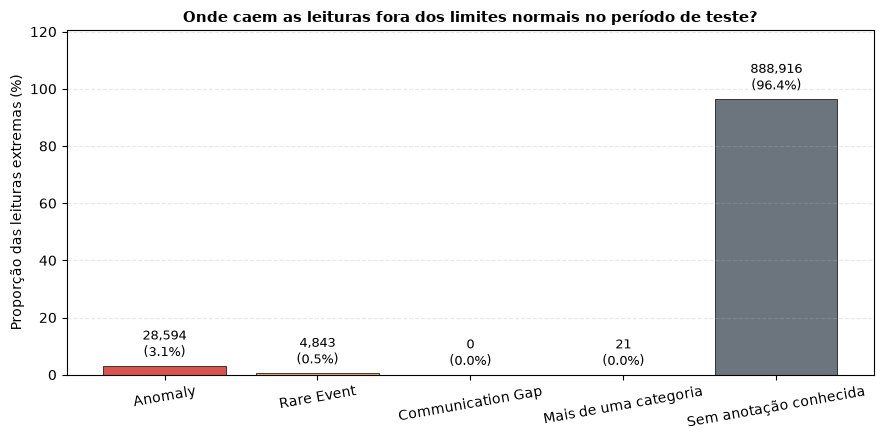

In [31]:
canal_extremos = "channel_41"
serie_extremos = pd.to_numeric(
    channels[canal_extremos].iloc[:, 0], errors="coerce"
)
indice_extremos = serie_extremos.index

# Dividimos o histórico em duas metades: referência (treino) e teste
corte_extremos = (
    indice_extremos.min() + (indice_extremos.max() - indice_extremos.min()) / 2
)
referencia_extremos = serie_extremos.loc[indice_extremos < corte_extremos]
teste_extremos = serie_extremos.loc[indice_extremos >= corte_extremos]

# Percentis de referência (1% inferior e 1% superior)
p01, p99 = referencia_extremos.quantile([0.01, 0.99])
mascara_extremos = (teste_extremos < p01) | (teste_extremos > p99)

# Timestamps em nanossegundos (int64)
timestamps_extremos_ns = teste_extremos.index.asi8[mascara_extremos.to_numpy()]

print(f"Limites P1 e P99 estimados no período inicial: {p01:.4f} e {p99:.4f}")
print(
    f"Total de leituras fora dos limites no período posterior: {len(timestamps_extremos_ns):,}"
)

# Filtramos os rótulos do canal
rotulos_extremos = labels_rotuladas.loc[
    (labels_rotuladas["Channel"] == canal_extremos)
    & labels_rotuladas["Category"].isin(
        ["Anomaly", "Rare Event", "Communication Gap"]
    ),
    ["Category", "StartTimeUTC", "EndTimeUTC"],
].copy()

# Garantimos conversão para datetime naive (sem fuso)
rotulos_extremos["inicio"] = pd.to_datetime(
    rotulos_extremos["StartTimeUTC"], utc=True
).dt.tz_localize(None)
rotulos_extremos["fim"] = pd.to_datetime(
    rotulos_extremos["EndTimeUTC"], utc=True
).dt.tz_localize(None)


def unir_intervalos_ns(grupo_rotulos: pd.DataFrame):
    """
    Une intervalos sobrepostos garantindo resolução estrita em NANOSSEGUNDOS (int64).
    Isso corrige a incompatibilidade entre datetime64[us] e datetime64[ns].
    """
    if grupo_rotulos.empty:
        return np.array([], dtype=np.int64), np.array([], dtype=np.int64)

    inicios = (
        grupo_rotulos["inicio"]
        .astype("datetime64[ns]")
        .astype("int64")
        .to_numpy()
    )
    fins = (
        grupo_rotulos["fim"].astype("datetime64[ns]").astype("int64").to_numpy()
    )

    pares = sorted(zip(inicios, fins))
    unidos = []
    for ini, fim in pares:
        if unidos and ini <= unidos[-1][1]:
            unidos[-1] = (unidos[-1][0], max(unidos[-1][1], fim))
        else:
            unidos.append((ini, fim))

    return np.array([p[0] for p in unidos], dtype=np.int64), np.array(
        [p[1] for p in unidos], dtype=np.int64
    )


def dentro_de_intervalos(
    timestamps_ns: np.ndarray, inicios_ns: np.ndarray, fins_ns: np.ndarray
) -> np.ndarray:
    """Verifica com busca binária quais timestamps caem dentro dos intervalos anotados."""
    if len(inicios_ns) == 0:
        return np.zeros(len(timestamps_ns), dtype=bool)
    posicoes = np.searchsorted(inicios_ns, timestamps_ns, side="right") - 1
    validas = posicoes >= 0
    resultado = np.zeros(len(timestamps_ns), dtype=bool)
    resultado[validas] = timestamps_ns[validas] <= fins_ns[posicoes[validas]]
    return resultado


# Cruzamento temporal por categoria
categorias_rotulo = ["Anomaly", "Rare Event", "Communication Gap"]
mascaras_por_categoria = {}
for cat in categorias_rotulo:
    grupo = rotulos_extremos.loc[rotulos_extremos["Category"] == cat]
    inicios_ns, fins_ns = unir_intervalos_ns(grupo)
    mascaras_por_categoria[cat] = dentro_de_intervalos(
        timestamps_extremos_ns, inicios_ns, fins_ns
    )

# Classificação de cada leitura extrema
classificacao_extremos = []
for i in range(len(timestamps_extremos_ns)):
    coincidentes = [
        cat for cat, masc in mascaras_por_categoria.items() if masc[i]
    ]
    if len(coincidentes) == 0:
        classificacao_extremos.append("Sem anotação conhecida")
    elif len(coincidentes) == 1:
        classificacao_extremos.append(coincidentes[0])
    else:
        classificacao_extremos.append("Mais de uma categoria")

# Tabela resumo dos resultados
ordem_contextos = [
    "Anomaly",
    "Rare Event",
    "Communication Gap",
    "Mais de uma categoria",
    "Sem anotação conhecida",
]
contagem_extremos = (
    pd.Series(classificacao_extremos)
    .value_counts()
    .reindex(ordem_contextos, fill_value=0)
)
percentuais_extremos = (contagem_extremos / len(classificacao_extremos)) * 100

tabela_extremos = pd.DataFrame(
    {
        "Leituras Extremas": contagem_extremos,
        "Percentual (%)": percentuais_extremos.round(2),
    }
)
display(tabela_extremos)

# Gráfico didático com cores semânticas e rótulos claros
fig, ax = plt.subplots(figsize=(9, 4.5))
cores_grafico = [
    CORES_CATEGORIAS.get(c, "#6c757d") for c in tabela_extremos.index
]

barras = ax.bar(
    tabela_extremos.index,
    tabela_extremos["Percentual (%)"],
    color=cores_grafico,
    edgecolor="black",
    linewidth=0.5,
)

# Adiciona etiquetas legíveis com contagem absoluta e percentual
ax.bar_label(
    barras,
    labels=[
        f"{n:,}\n({pct:.1f}%)"
        for n, pct in zip(
            tabela_extremos["Leituras Extremas"],
            tabela_extremos["Percentual (%)"],
        )
    ],
    padding=4,
    fontsize=9,
)

ax.set_ylim(0, max(1, float(tabela_extremos["Percentual (%)"].max()) * 1.25))
ax.set_ylabel("Proporção das leituras extremas (%)", fontsize=10)
ax.set_title(
    "Onde caem as leituras fora dos limites normais no período de teste?",
    fontsize=11,
    fontweight="bold",
)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

#### 5. Detecção de Anomalias com Limites

**5.1 Se ajustarmos uma regra robusta no período inicial e a aplicarmos no período posterior, quantas leituras serão sinalizadas, quantos episódios isso forma e com quais categorias anotadas coincidem?**

In [32]:
canal_detector = "channel_41"
serie_detector = (
    pd.to_numeric(channels[canal_detector].iloc[:, 0], errors="coerce")
    .dropna()
    .sort_index()
)

# Divisão temporal (50% treino / 50% teste)
corte_detector = serie_detector.index.min() + (
    serie_detector.index.max() - serie_detector.index.min()
) / 2
serie_treino = serie_detector.loc[serie_detector.index < corte_detector]
serie_teste = serie_detector.loc[serie_detector.index >= corte_detector]

# 1. Rótulos do canal no treino e no teste
rotulos_canal = labels_rotuladas.loc[
    labels_rotuladas["Channel"] == canal_detector
].copy()
rotulos_canal["inicio"] = pd.to_datetime(
    rotulos_canal["StartTimeUTC"], utc=True
).dt.tz_localize(None)
rotulos_canal["fim"] = pd.to_datetime(
    rotulos_canal["EndTimeUTC"], utc=True
).dt.tz_localize(None)

# 2. CALIBRAÇÃO NÃO CONTAMINADA:
# Selecionamos apenas os pontos do treino que NÃO são zero e NÃO caem em eventos rotulados
inicios_treino_ns, fins_treino_ns = unir_intervalos_ns(
    rotulos_canal[rotulos_canal["inicio"] < corte_detector]
)
mascara_em_evento_treino = dentro_de_intervalos(
    serie_treino.index.asi8, inicios_treino_ns, fins_treino_ns
)
treino_limpo = serie_treino.loc[(serie_treino > 0) & (~mascara_em_evento_treino)]

mediana_treino = float(treino_limpo.median())
mad_treino = float((treino_limpo - mediana_treino).abs().median())
escala_mad = 1.4826 * mad_treino  # Estimador robusto do desvio padrão

print(f"--- Calibração Limpa (sem zeros e sem eventos) ---")
print(f"Mediana nominal: {mediana_treino:.4f}")
print(f"Escala MAD (desvio robusto): {escala_mad:.5f}\n")

# 3. Aplicação no período de teste
# Nota: Tratamos zeros como categoria própria (possível perda de telemetria)
score_teste = (serie_teste - mediana_treino).abs() / escala_mad
alerta_limite = (score_teste > 3) & (serie_teste > 0)  # Limiar de 3 desvios
alerta_zero = serie_teste == 0
alerta_total = alerta_limite | alerta_zero

print(f"Total de leituras no teste: {len(serie_teste):,}")
print(
    f"Leituras com desvio > 3 MAD: {int(alerta_limite.sum()):,} ({100*alerta_limite.mean():.2f}%)"
)
print(f"Leituras com valor zero: {int(alerta_zero.sum()):,}")

# 4. AGRUPAMENTO EM EPISÓDIOS (Tolerância temporal de 30 minutos)
timestamps_alertas = serie_teste.index[alerta_total]
episodios = []

if len(timestamps_alertas) > 0:
    janela_tolerancia = pd.Timedelta(minutes=30)
    inicio_ep = timestamps_alertas[0]
    fim_ep = timestamps_alertas[0]
    pontos_ep = 1

    for ts in timestamps_alertas[1:]:
        if ts - fim_ep <= janela_tolerancia:
            fim_ep = ts
            pontos_ep += 1
        else:
            episodios.append(
                {"inicio": inicio_ep, "fim": fim_ep, "leituras": pontos_ep}
            )
            inicio_ep = ts
            fim_ep = ts
            pontos_ep = 1
    episodios.append(
        {"inicio": inicio_ep, "fim": fim_ep, "leituras": pontos_ep}
    )

df_episodios = pd.DataFrame(episodios)

# 5. Cruzamento dos episódios com os rótulos reais
rotulos_teste = rotulos_canal.loc[rotulos_canal["fim"] >= corte_detector].copy()


def classificar_episodio(row):
    intersecoes = rotulos_teste.loc[
        (rotulos_teste["inicio"] <= row["fim"])
        & (rotulos_teste["fim"] >= row["inicio"])
    ]
    cats = intersecoes["Category"].dropna().unique()
    if len(cats) == 0:
        return "Sem anotação conhecida"
    elif len(cats) == 1:
        return cats[0]
    return "Múltiplas categorias"


df_episodios["categoria"] = df_episodios.apply(classificar_episodio, axis=1)

print(f"\n--- Resumo dos Episódios de Alerta (Unidos por janela de 30 min) ---")
print(f"Total de episódios consolidados: {len(df_episodios)}")
display(df_episodios["categoria"].value_counts().to_frame("Total de Episódios"))

# 6. Avaliação por Evento: Quantos eventos reais dispararam pelo menos 1 alerta?
print("\n--- Sensibilidade por Evento Rotulado (Período de Teste) ---")
resumo_eventos = []
for cat in ["Anomaly", "Rare Event"]:
    eventos_cat = rotulos_teste.loc[rotulos_teste["Category"] == cat]
    total_ev = len(eventos_cat)
    detectados = 0
    for _, ev in eventos_cat.iterrows():
        # Houve alerta dentro do intervalo do evento?
        if alerta_total.loc[ev["inicio"] : ev["fim"]].any():
            detectados += 1
    pct = (detectados / total_ev * 100) if total_ev > 0 else 0
    resumo_eventos.append(
        {
            "Categoria": cat,
            "Eventos no Teste": total_ev,
            "Detectados (>= 1 alerta)": detectados,
            "Taxa de Detecção (%)": round(pct, 1),
        }
    )
display(pd.DataFrame(resumo_eventos).set_index("Categoria"))

# ------------------------------------------------------------------------------
# 7. Pontuacao maxima por evento rotulado (periodo de teste) -- alimenta a 5.2
# Para cada evento anotado no teste, pega o maior escore (desvio/MAD) atingido
# dentro do seu intervalo. Usado para comparar Anomalia x Evento Raro no boxplot.
# ------------------------------------------------------------------------------
linhas_scores_eventos = []
for _, ev in rotulos_teste.iterrows():
    cat = ev["Category"]
    if cat not in ("Anomaly", "Rare Event"):
        continue
    trecho = score_teste.loc[ev["inicio"] : ev["fim"]]
    if len(trecho) == 0:
        continue
    linhas_scores_eventos.append(
        {
            "ID": ev["ID"],
            "Category": cat,
            "score_maximo": float(trecho.max()),
        }
    )
df_scores_eventos = pd.DataFrame(linhas_scores_eventos)

print("\n--- Escore maximo por evento rotulado (periodo de teste) ---")
display(
    df_scores_eventos.groupby("Category")["score_maximo"]
    .agg(n="count", mediana="median", maximo="max")
    .round(2)
)


--- Calibração Limpa (sem zeros e sem eventos) ---
Mediana nominal: 0.8110
Escala MAD (desvio robusto): 0.00698

Total de leituras no teste: 7,661,983
Leituras com desvio > 3 MAD: 27,731 (0.36%)
Leituras com valor zero: 2,936

--- Resumo dos Episódios de Alerta (Unidos por janela de 30 min) ---
Total de episódios consolidados: 87


,Total de Episódios
categoria,
Sem anotação conhecida,48
Anomaly,33
Rare Event,5
Múltiplas categorias,1



--- Sensibilidade por Evento Rotulado (Período de Teste) ---


,Eventos no Teste,Detectados (>= 1 alerta),Taxa de Detecção (%)
Categoria,,,
Anomaly,32,27,84.4
Rare Event,74,6,8.1



--- Escore maximo por evento rotulado (periodo de teste) ---


,n,mediana,maximo
Category,,,
Anomaly,32,21.36,116.18
Rare Event,74,1.57,8.99


**5.2 Os scores da regra robusta diferem entre intervalos de teste anotados como `Anomaly` e `Rare Event` no `channel_41`?**

> Vamos resumir score máximo e mediano por ID, usando apenas a parte dos intervalos dentro do período posterior. Eventos pontuais sem uma amostra exatamente no timestamp serão contados como sem score disponível; não vamos deslocar o rótulo para favorecer o detector.

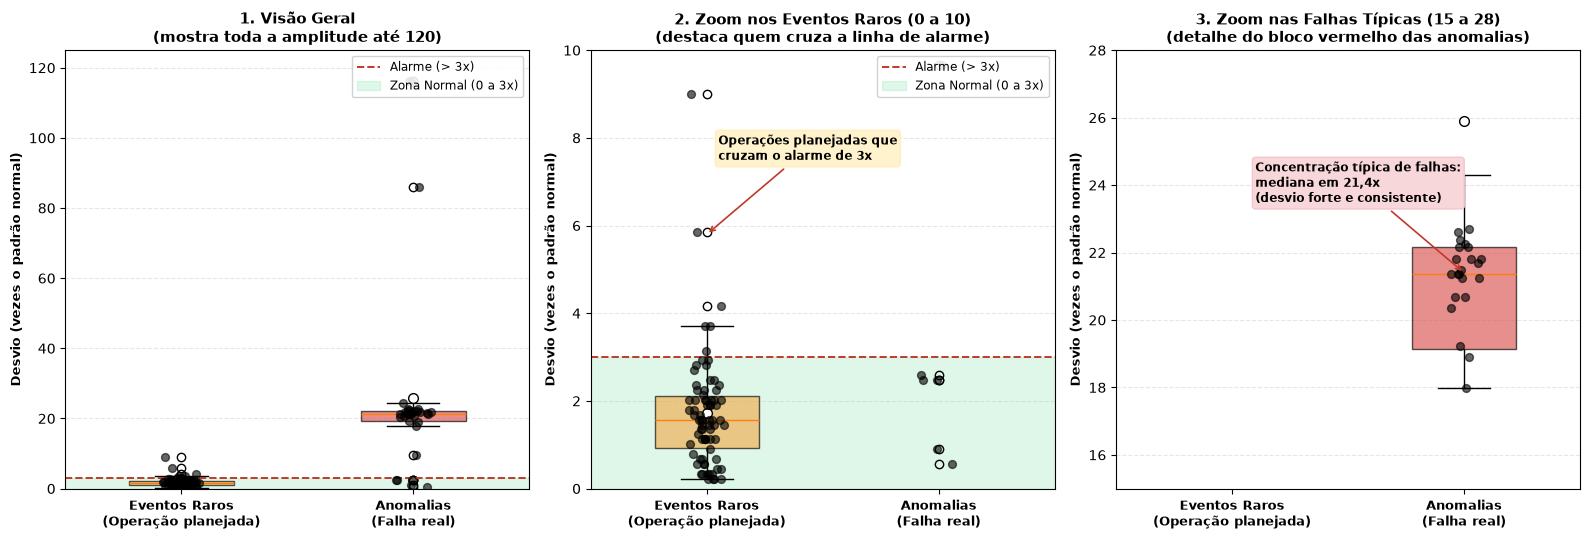

In [33]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5.5))

categorias_plot = ["Rare Event", "Anomaly"]
rotulos_legiveis = [
    "Eventos Raros\n(Operação planejada)",
    "Anomalias\n(Falha real)",
]
cores_box = [CORES_CATEGORIAS["Rare Event"], CORES_CATEGORIAS["Anomaly"]]

dados_plot = [
    df_scores_eventos.loc[
        df_scores_eventos["Category"] == cat, "score_maximo"
    ].dropna()
    for cat in categorias_plot
]


# Função que desenha o boxplot padronizado em qualquer painel
def desenhar_painel(ax, titulo, subtitulo, limite_y, mostrar_alarme=True):
    bp = ax.boxplot(
        dados_plot,
        patch_artist=True,
        widths=0.45,
        showmeans=True,
        meanprops={
            "marker": "o",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
            "markersize": 7,
        },
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(rotulos_legiveis, fontsize=9.5, fontweight="bold")

    for patch, cor in zip(bp["boxes"], cores_box):
        patch.set_facecolor(cor)
        patch.set_alpha(0.65)

    # Pontos reais individuais com posição reprodutível
    for i, valores in enumerate(dados_plot):
        np.random.seed(42)
        x = np.random.normal(i + 1, 0.04, size=len(valores))
        ax.scatter(x, valores, color="black", alpha=0.6, s=32, zorder=3)

    if mostrar_alarme:
        ax.axhline(
            3,
            color="#c0392b",
            linestyle="--",
            linewidth=1.4,
            label="Alarme (> 3x)",
        )
        ax.axhspan(
            0, 3, color="#2ecc71", alpha=0.15, label="Zona Normal (0 a 3x)"
        )
        ax.legend(loc="upper right", framealpha=0.9, fontsize=8.5)

    ax.set_ylabel(
        "Desvio (vezes o padrão normal)", fontsize=9.5, fontweight="bold"
    )
    ax.set_title(f"{titulo}\n{subtitulo}", fontsize=10.5, fontweight="bold")
    ax.set_ylim(limite_y)
    ax.grid(axis="y", linestyle="--", alpha=0.3)


# 1. Painel da Esquerda: Visão Geral Completa
desenhar_painel(
    ax1,
    titulo="1. Visão Geral",
    subtitulo="(mostra toda a amplitude até 120)",
    limite_y=(0, 125),
    mostrar_alarme=True,
)

# 2. Painel do Meio: Zoom nos Eventos Raros e Linha de Alarme (0 a 10)
desenhar_painel(
    ax2,
    titulo="2. Zoom nos Eventos Raros (0 a 10)",
    subtitulo="(destaca quem cruza a linha de alarme)",
    limite_y=(0, 10),
    mostrar_alarme=True,
)

ax2.annotate(
    "Operações planejadas que\ncruzam o alarme de 3x",
    xy=(1, 5.8),
    xytext=(1.05, 7.5),
    arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.2),
    fontsize=8.5,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.25", fc="#fff3cd", ec="#ffeeba"),
)

# 3. Painel da Direita: Zoom nas Anomalias Típicas (15 a 28)
desenhar_painel(
    ax3,
    titulo="3. Zoom nas Falhas Típicas (15 a 28)",
    subtitulo="(detalhe do bloco vermelho das anomalias)",
    limite_y=(15, 28),
    mostrar_alarme=False,  # O alarme (3) fica bem abaixo dessa faixa
)

# Anotação no bloco vermelho das anomalias
ax3.annotate(
    "Concentração típica de falhas:\nmediana em 21,4x\n(desvio forte e consistente)",
    xy=(2, 21.4),
    xytext=(1.1, 23.5),
    arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.2),
    fontsize=8.5,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.25", fc="#f8d7da", ec="#f5c6cb"),
)

plt.tight_layout()
plt.show()